# 모듈 2 · NLP 미니프로젝트 — BERT 기반 한국어 의미 검색 시스템 개발 및 성능 비교

**기간:** 2일·총 16교시 · **체크포인트:** Day 1 `CP-01~06`, Day 2 `CP-07~10`  
**검색 모델:** TF-IDF · `klue/bert-base` · 한국어 Sentence-BERT  
**최종 결과물:** `search_docs()` + 검색 성능 보고서 + 기술적 의사결정 기록(ADR)

> 이 프로젝트는 GPT로 답변을 생성하거나 BERT를 재학습하는 프로젝트가 아닙니다. **문서의 표현 → 유사도 계산 → Top-k 검색 → 정답 평가 → 오류 분석 → 최종 검색 방식 선정**을 직접 개발합니다.
>
> **학생용 안내:** `[학생 구현]` 셀의 `TODO`를 작성하고 `raise NotImplementedError(...)`를 지운 뒤 `[공통 검증]` 셀을 실행하세요. `[기록]`으로 표시된 Markdown 셀은 실제 결과를 보고 직접 작성합니다. `생각해 볼 질문`은 별도 제출이 아닙니다.


## 00. 환경 설치와 세션 초기화 복구

GPU 세션이 초기화되더라도 첫 코드 셀부터 다시 실행할 수 있도록 구성했습니다. 패키지·모델 가중치·데이터가 없는 경우 자동으로 준비하며, 이미 저장된 파일은 재사용합니다.


**환경 설치(공통).** 필요한 Python 패키지를 한 번에 점검하고 누락되거나 호환 범위를 벗어난 패키지만 설치합니다. GPU 이미지에 이미 설치된 CUDA용 PyTorch는 가능한 한 유지하며, 설치 후 CUDA 상태를 확인합니다.


In [8]:
# [공통] 00-1 — 필요한 패키지 자동 설치
import sys, subprocess, importlib.metadata as im
from importlib.util import find_spec

# Python 패키지가 GPU 세션 초기화로 사라진 경우에도 첫 셀부터 복구합니다.
# RunPod GPU 이미지의 PyTorch/CUDA 조합은 가능하면 변경하지 않습니다.
requirements = [
    ('torch', 'torch>=2.2', '2.2'),
    ('numpy', 'numpy>=1.24', '1.24'),
    ('pandas', 'pandas>=2.0', '2.0'),
    ('matplotlib', 'matplotlib>=3.7', '3.7'),
    ('sklearn', 'scikit-learn>=1.3', '1.3'),
    ('transformers', 'transformers>=4.46,<5', '4.46'),
    ('datasets', 'datasets>=3.0,<5', '3.0'),
    ('sentence_transformers', 'sentence-transformers>=3.0,<6', '3.0'),
    ('safetensors', 'safetensors>=0.4', '0.4'),
]

# 설치 확인에는 표준 라이브러리만 사용합니다.
to_install = []
for module, spec, min_version in requirements:
    if find_spec(module) is None:
        to_install.append(spec)
    else:
        try:
            package = {'sklearn': 'scikit-learn', 'sentence_transformers': 'sentence-transformers'}.get(module, module)
            version = im.version(package)
            major_minor = tuple(int(x) for x in version.split('.')[:2])
            required = tuple(int(x) for x in min_version.split('.'))
            if major_minor < required or (module in ('transformers','datasets') and int(version.split('.')[0]) >= 5):
                to_install.append(spec)
        except (im.PackageNotFoundError, ValueError):
            to_install.append(spec)

if to_install:
    print('설치/갱신:', ', '.join(to_install))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',  *to_install])
else:
    print('필수 패키지가 이미 준비되어 있습니다.')

# 이미 import한 구버전 라이브러리가 변경된 경우에는 커널 재시작 후 다시 실행하세요.
print('Python:', sys.version.split()[0])


필수 패키지가 이미 준비되어 있습니다.
Python: 3.11.17


**작업 폴더와 장치 확인(공통).** `/workspace`가 있으면 프로젝트 파일을 그 아래에, 그 외 환경은 현재 작업 폴더 아래에 보관합니다. 모든 파일·폴더는 처음 실행할 때 자동으로 생성되며 추론 결과는 재실행 시 캐시를 재사용합니다.


In [9]:
# [공통] 00-2 — 프로젝트 경로·GPU·캐시 설정
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = (Path('/workspace') if Path('/workspace').is_dir() else Path.cwd()) / 'nlp_bert_mini'
DATA_RAW = ROOT / 'data' / 'raw'
DATA_PROCESSED = ROOT / 'data' / 'processed'
WEIGHTS = ROOT / 'weights'
CACHE = ROOT / 'outputs' / 'cache'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'
DOCS = ROOT / 'docs'
for folder in [DATA_RAW, DATA_PROCESSED, WEIGHTS, CACHE, TABLES, FIGURES, REPORTS, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(WEIGHTS / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('실습 루트:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.')

# [공통] CP-08의 Sentence-BERT 가중치(pytorch_model.bin)는 PyTorch 버전이 낮으면 읽지 못할 수 있어 미리 확인합니다.
try:
    _torch_major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
except ValueError:
    _torch_major_minor = None
if _torch_major_minor is not None and _torch_major_minor < (2, 6):
    print('[주의] PyTorch가 2.6 미만입니다. Day 2의 CP-08에서 Sentence-BERT 로딩이 실패할 수 있으니 강사에게 알려 주세요.')


실습 루트: c:\AiStudy\workspace-ai\ai-mini-projects\mini-project-02\code\nlp_bert_mini
PyTorch: 2.15.0+cpu | Device: cpu
GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.


### 세션 초기화 시 재실행 방법

1. GitHub에는 **작성한 Notebook과 최종 문서**를 저장하세요. 대용량 모델·원본 데이터는 업로드하지 않습니다.
2. 다음 날 Notebook을 내려받아 **00번 환경 셀부터 순서대로 실행**하면 폴더와 다운로드 데이터가 자동으로 준비됩니다.
3. `/workspace`가 영구 볼륨에 연결되어 있으면 캐시를 재사용합니다. 컨테이너가 삭제되는 환경에서는 다운로드와 임베딩 계산이 다시 진행될 수 있습니다.
4. CP-01~09는 Validation 질문만 사용합니다. **Test 질문의 정답은 CP-10에서 처음 열어 최종 평가**합니다.

**저장 위치:** `data/processed/` (문서·질문), `weights/` (모델 캐시), `outputs/cache/` (문서 벡터), `outputs/tables/` (성능표), `outputs/figures/` (그래프), `outputs/reports/` (결정·최종 평가).


# Day 1 — 한국어 문서 검색기 구현

**목표:** 데이터를 탐색하고 TF-IDF 검색기와 BERT 검색기를 직접 구현합니다. Day 1의 함수들은 Day 2 평가·모델 비교에서 그대로 사용합니다.

---
## CP-01. 문서·질문·정답 구조 분석 및 검색 성능 가설 수립

이번 프로젝트는 KLUE-MRC의 질문–문단 데이터를 **검색 문제**로 다시 구성합니다. 원래 KLUE-MRC는 독해/정답 구간 추출 데이터이며, 본 프로젝트는 정답 문단 하나를 연결하는 별도 검색 평가 데이터이므로 공식 KLUE-MRC 점수와 다릅니다.


**KLUE-MRC 자동 데이터 준비(공통).** 공개 데이터에서 답이 존재하는 질문과 중복되지 않는 문단을 선별해 문단 200개, Validation 질문 60개, 보류 Test 질문 20개를 만듭니다. 질문과 문단은 문서 ID로 연결되며, Test 정답은 CP-10 이전에는 열지 않습니다.


In [10]:
# [공통] CP-01 — 검색용 Corpus / Validation / 보류 Test 자동 준비
from datasets import load_dataset

CORPUS_FILE = DATA_PROCESSED / 'corpus_200.csv'
VALID_FILE = DATA_PROCESSED / 'questions_validation_60.csv'
TEST_FILE = DATA_PROCESSED / 'questions_test_20.csv'
META_FILE = DATA_PROCESSED / 'dataset_meta.json'

# KLUE-MRC 공식 Hugging Face 데이터셋 (validation split만 사용)
# 기존 데이터가 저장되어 있으면 다시 다운로드·선별하지 않습니다.
if not all(f.is_file() for f in (CORPUS_FILE, VALID_FILE, TEST_FILE, META_FILE)):
    raw = load_dataset('klue/klue', 'mrc', split='validation', cache_dir=str(DATA_RAW))
    eligible = []
    seen_contexts = set()
    seen_questions = set()
    for r in raw:
        if bool(r['is_impossible']):
            continue
        context, question = str(r['context']).strip(), str(r['question']).strip()
        if len(context) < 150 or not question or context in seen_contexts or question in seen_questions:
            continue
        answers = r['answers']
        answer_texts = answers.get('text', []) if isinstance(answers, dict) else []
        answer_starts = answers.get('answer_start', []) if isinstance(answers, dict) else []
        if not answer_texts:
            continue
        answer_text = str(answer_texts[0]).strip()
        if not answer_text or answer_text not in context:
            continue
        # ### 답변이 포함된 500자 이내의 문단으로 줄입니다.
        # ### (토큰 수가 MAX_LENGTH를 넘는 문단은 BERT에 넣을 때 뒷부분이 잘릴 수 있습니다.)
        answer_pos = context.find(answer_text)
        left = max(0, min(answer_pos - 180, max(0, len(context) - 500)))
        snippet = context[left:left + 500].strip()
        if answer_text not in snippet:
            continue
        eligible.append({'title': str(r.get('title', '')), 'text': snippet,
                         'question': question, 'guid': str(r['guid'])})
        seen_contexts.add(context)
        seen_questions.add(question)

    assert len(eligible) >= 200, f'선별 가능한 문단이 200개보다 적습니다: {len(eligible)}'
    rng = np.random.default_rng(SEED)
    selected = [eligible[i] for i in rng.choice(len(eligible), size=200, replace=False)]
    docs = [{'doc_id': f'D{i:03d}', 'title': r['title'], 'text': r['text']}
            for i, r in enumerate(selected)]
    corpus_out = pd.DataFrame(docs)
    candidate_idx = rng.permutation(200)[:80]
    qrows = [{'question': selected[int(idx)]['question'],
              'relevant_doc_id': f'D{int(idx):03d}'} for idx in candidate_idx]
    validation_out = pd.DataFrame([
        {'query_id': f'QV{i+1:03d}', **row} for i, row in enumerate(qrows[:60])])
    test_out = pd.DataFrame([
        {'query_id': f'QT{i+1:03d}', **row} for i, row in enumerate(qrows[60:])])

    corpus_out.to_csv(CORPUS_FILE, index=False, encoding='utf-8-sig')
    validation_out.to_csv(VALID_FILE, index=False, encoding='utf-8-sig')
    test_out.to_csv(TEST_FILE, index=False, encoding='utf-8-sig')
    META_FILE.write_text(json.dumps({
        'source': 'klue/klue · mrc · validation', 'seed': SEED,
        'num_documents': 200, 'num_validation_queries': 60, 'num_test_queries': 20,
        'sampling': 'unique contexts; one labeled relevant snippet per question',
        'notes': '수업용 단일 정답 문단 검색 세트. KLUE-MRC의 공식 검색 벤치마크가 아님.'
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    print('KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.')
else:
    print('저장된 프로젝트 데이터셋을 재사용합니다.')

corpus_df = pd.read_csv(CORPUS_FILE, dtype={'doc_id': str}).fillna('')
valid_df = pd.read_csv(VALID_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')



assert len(corpus_df) == 200 and len(valid_df) == 60
assert valid_df['relevant_doc_id'].isin(corpus_df['doc_id']).all()
assert corpus_df['doc_id'].is_unique
print('문서:', len(corpus_df), '| Validation 질문:', len(valid_df), '| 별도 보류 Test: 20문항')
display(corpus_df[['doc_id', 'title', 'text']].head(3))
display(valid_df.head(3))


c:\AiStudy\workspace-ai\ai-mini-projects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\AiStudy\workspace-ai\ai-mini-projects\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\AiStudy\workspace-ai\ai-mini-projects\mini-project-02\code\nlp_bert_mini\weights\huggingface\hub\datasets--klue--klue. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Deve

KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.
문서: 200 | Validation 질문: 60 | 별도 보류 Test: 20문항


,doc_id,title,text
0,D000,관 (쓰개),13세기 초 인도 남부에서 채굴된 코이누르 다이아몬드는 무굴제국 등 여러 왕가의 소...
1,D001,도망자 (1995년 영화),"캄보디아 내전 시기. CIA 소속 첩보원인 아화, 아상, 그리고 뇌룡 3인은 캄보디..."
2,D002,기업들 “공공료 다 올려놓고 …”,정부 출범 초마다 어김없이 반복되는 물가 안정 대책에 업계는 바짝 긴장하고 있다. ...


,query_id,question,relevant_doc_id
0,QV001,종교 개혁 전 영국에서 인기를 끌었던 헌신은?,D015
1,QV002,세 종류의 배터리 용량을 선택할 수 있는 폭스바겐의 전기차 모델은?,D092
2,QV003,70억달러가 국비로 충당된 올림픽은?,D022


**데이터 탐색·시각화(학생 구현).** 질문과 문단의 글자 수를 계산하고 길이 분포를 그림으로 정리합니다. 관찰 결과를 바탕으로 TF-IDF와 BERT가 각각 어떤 질문에서 유리할지 예상하고 CP-09에서 다시 확인합니다.


=== 문서(Corpus) 길이 통계 ===
count    200.00000
mean     499.66000
std        0.53463
min      498.00000
25%      499.00000
50%      500.00000
75%      500.00000
max      500.00000
Name: char_length, dtype: float64

=== 질문(Validation) 길이 통계 ===
count    60.000000
mean     29.216667
std       8.427340
min      13.000000
25%      23.750000
50%      28.000000
75%      36.000000
max      54.000000
Name: char_length, dtype: float64



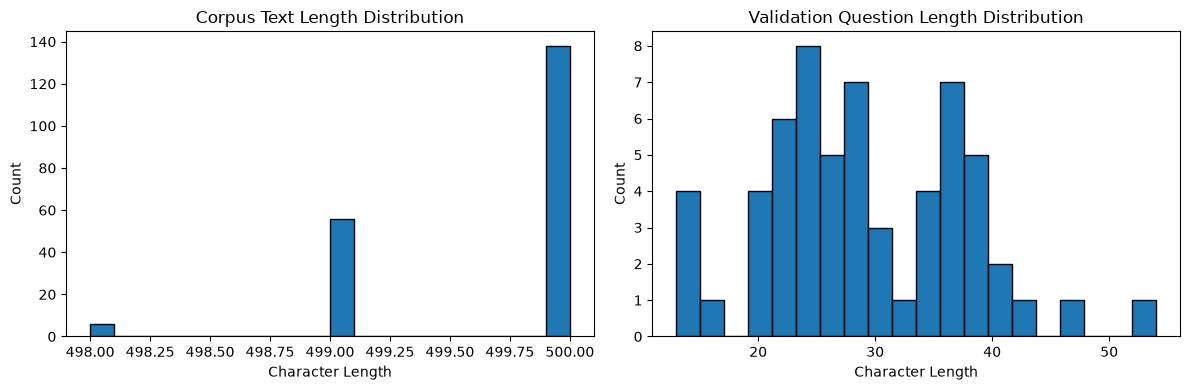

In [11]:
# [학생 구현] CP-01 — 데이터 길이 분석 및 시각화

# EDA(통계 분석) 및 전처리 테스트용 사본 생성 (원본 데이터 훼손 방지)
corpus_stats = corpus_df.copy()    # 검색 대상 문서 집합 (한국어 문단 200개)
valid_stats = valid_df.copy()      # 검증용 질문 데이터셋 (60개)

# TODO 1-1. corpus_stats['char_length']에 문서 text의 글자 수를 계산해 넣으세요.
# - .astype(str): 결측치나 다른 타입이 섞여 있어도 문자로 바꿈
# - .str.len(): 각 문서의 글자 수(띄어쓰기·문장부호 포함)를 계산
corpus_stats['char_length'] = corpus_stats['text'].astype(str).str.len()
# --------

# TODO 1-2. valid_stats['char_length']에 질문 question의 글자 수를 계산해 넣으세요.
valid_stats['char_length'] = valid_stats['question'].astype(str).str.len()
# --------

# TODO 1-3. describe()로 문서·질문 길이 통계를 출력하세요.
# - .describe() 개수, 평균, 표준편차, 최솟값, 사분위수, 최댓값 한번에 요약
print("=== 문서(Corpus) 길이 통계 ===")
print(corpus_stats['char_length'].describe())  

print()

print("=== 질문(Validation) 길이 통계 ===")
print(valid_stats['char_length'].describe())
# --------

print()
# TODO 1-4. 두 길이 분포를 histogram으로 시각화하고 FIGURES에 저장하세요.
#             matplotlib의 plt.subplots(), ax.hist(), fig.savefig()를 사용합니다.

# 1)그래프 도화지 준비 
#   - 1줄에 2개 배치, 전체 가로 12 × 세로 4인치)
#   - axes: 개별 그래프 영역 배열 (axes[0], axes[1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4)) 


# 2)첫 번째(axes[0]) 그래프
# bins=20: 길이 구간을 20개로 나누어 막대를 그립니다.
# edgecolor='black': 막대 테두리 검은색 옵션
axes[0].hist(corpus_stats['char_length'], bins=20, edgecolor='black')
axes[0].set_title('Corpus Text Length Distribution')  # 왼쪽 그래프 제목
axes[0].set_xlabel('Character Length')                # 가로축(글자 수) 이름
axes[0].set_ylabel('Count')                           # 세로축(문서 개수) 이름


# 3)두 번째(axes[1]) 그래프
axes[1].hist(valid_stats['char_length'], bins=20, edgecolor='black')
axes[1].set_title('Validation Question Length Distribution')  # 오른쪽 그래프 제목
axes[1].set_xlabel('Character Length')                        # 가로축(글자 수) 이름
axes[1].set_ylabel('Count')                                   # 세로축(질문 개수) 이름


# 4)그려진 그래프 라벨 겹치지 않게조정
plt.tight_layout()

# 5) 그래프를 이미지 파일로 저장 및 출력
fig.savefig(FIGURES / 'cp01_length_distribution.png', dpi=150)
plt.show()


#raise NotImplementedError('CP-01 길이 분석·그래프 TODO를 완성하세요.')


**질문–정답 문단 겹침 분석(공통).** TF-IDF는 질문과 문단에 같은 글자 묶음이 많이 나올수록 유리합니다. 질문의 글자 2개 묶음(2-gram) 가운데 정답 문단에도 나오는 비율을 질문마다 계산해 `valid_overlap`에 저장합니다. 겹침 비율이 낮은 질문은 문단과 다른 표현으로 물어본 질문입니다. 코드는 제공되며, 학생들은 표를 읽고 아래 기록을 작성합니다. 이 표는 CP-09에서 검색에 실패한 질문과 다시 비교합니다.

In [12]:
# [공통] CP-01 — 질문과 정답 문단의 글자 겹침 비율 (Validation 질문만 사용)

def char_bigrams(text):
    """어절 안에서 만든 글자 2개 묶음의 집합. 예: '검색 성능' → {'검색', '성능'}"""
    return {word[i:i + 2] for word in str(text).split() for i in range(len(word) - 1)}


def overlap_ratio(question, document):
    """질문의 글자 2-gram 중 문단에도 등장하는 비율(0~1)."""
    question_grams = char_bigrams(question)
    if not question_grams:
        return 0.0
    return len(question_grams & char_bigrams(document)) / len(question_grams)


_doc_text = corpus_df.set_index('doc_id')['text']
valid_overlap = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
valid_overlap['overlap'] = [overlap_ratio(q, _doc_text[d])
                            for q, d in zip(valid_overlap['question'], valid_overlap['relevant_doc_id'])]
print('질문–정답 문단 겹침 비율 통계:')
display(valid_overlap['overlap'].describe().to_frame('겹침 비율').round(3))
print('겹침 비율이 가장 낮은 질문 5개:')
display(valid_overlap.sort_values('overlap').head(5)[['query_id', 'question', 'overlap']].round(3))
valid_overlap.to_csv(TABLES / 'cp01_validation_overlap.csv', index=False, encoding='utf-8-sig')
print('겹침 비율이 가장 높은 질문 5개:')
display(valid_overlap.sort_values('overlap', ascending=False).head(5)[['query_id', 'question', 'overlap']].round(3))

질문–정답 문단 겹침 비율 통계:


,겹침 비율
count,60.000
mean,0.474
std,0.175
min,0.158
25%,0.333
50%,0.462
75%,0.601
max,0.882


겹침 비율이 가장 낮은 질문 5개:


,query_id,question,overlap
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,0.158
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,0.167
51,QV052,한국전쟁은 남한이 일으켰다고 주장한 사람은?,0.200
50,QV051,누구나 쇼핑몰을 할 수 있게 된 것 같은 변화가 제조업에서도 일어날 수 있는 것은 ...,0.217
8,QV009,영국은 어느나라와의 싸움에서 승리해 코이누르 보석을 습득했나요?,0.227


겹침 비율이 가장 높은 질문 5개:


,query_id,question,overlap
3,QV004,그리스가 제출한 구제금융안의 재정지출 감축 규모는?,0.882
29,QV030,한·뉴질랜드 FTA가 정식서명 절차를 마친 달은?,0.812
10,QV011,2011년 기준 전국의 장기 미집행 도시계획시설 중 사유지에 해당하는 면적은?,0.792
21,QV022,12월 25일까지 네이버 시리즈온에서 무료로 감상할 수 있는 영화는?,0.762
42,QV043,정부가 통신시장에 요금인가제를 마련한 해는?,0.733


**[기록] 결과 해석 — CP-01**

* 문서 길이와 질문 길이 분포에서 관찰한 특징  
  -문서 200개 모두 498-500자 (평균 499.66, 표준편차 0.53)  
  -500자 138개, 499자 56개, 498자 6개  
  -코드가 500자 윈도우로 자른 결과이며 자연 분포가 아님  
  -문서 길이가 일정해 길이는 성능 차이의 변수가 아님  
  -TF-IDF 길이 정규화 효과도 문서 간 차이 거의 없음  
  -질문은 평균 29.2자, 중앙값 28자, 범위 13-54자  
  -대부분 20-40자에 분포  
  -질문이 문서의 약 1/17 길이라 단서 단어가 적음  
  -단어 하나의 일치 여부가 점수에 크게 영향  
  
* 질문–정답 문단 겹침 비율 분포에서 관찰한 특징  
  -평균 0.474, 중앙값 0.462, 표준편차 0.175  
  -범위 0.158-0.882, 중간 50%는 0.333-0.601  
  -겹침 0인 질문 없음  
  -높은 쪽(0.73-0.88): 고유명사·숫자·전문용어가 문단 표현 그대로 포함 (예: 그리스 구제금융안, 한·뉴질랜드 FTA, 요금인가제)  
  -낮은 쪽(0.16-0.23): 바꿔 말하기, 간접 지칭, 비유가 포함 (예: "천의 여왕으로 불리는 인물", "싸움에 대비한 체육")  
  -문장부호 미제거로 수치가 다소 낮게 계산됨 (참고용 메모)  
  
* 가설 1 — TF-IDF가 잘 찾을 것으로 예상하는 질문과 이유  
  -대상: 겹침이 높고 고유명사·숫자·전문용어가 문단과 같은 형태로 들어간 질문 (QV004, QV030, QV043)  
  -이유 1: 문자열 일치 기반이라 드문 단어가 맞으면 IDF 가중치가 커짐  
  -이유 2: 200개 문서가 서로 다른 주제라 방해 문서가 적음  
  -겹침이 낮아도 희귀어 하나가 일치하면 성공 가능 (QV009의 "코이누르")  
  -따라서 핵심 조건은 "희귀한 고유어의 그대로 일치"  
  -한국어는 조사 때문에 공백 토큰화보다 글자 n-gram이 유리할 것으로 예상 (이후 실험에서 확인)  
  
* 가설 2 — BERT 기반 검색에서 유리하거나 불리할 것 같은 질문과 이유  
  -유리: 겹침이 낮고 같은 뜻을 다르게 표현한 질문 (QV018, QV046, QV052)  
  -유리한 이유: 의미가 가까우면 글자가 달라도 벡터가 가까워짐  
  -불리 1: 숫자·날짜 일치가 핵심인 질문 (QV011, QV022)  
  -불리 1의 이유: 연도·날짜만 다른 비슷한 문단을 구분하기 어려움  
  -불리 2: 500자 문단이 MAX_LENGTH(256토큰)를 넘으면 뒷부분이 잘림  
  -불리 2의 이유: 정답 단서가 뒤쪽에 있으면 임베딩에 반영 안 됨 (실제 잘리는 문서 수는 미확인)  
  -불확실: 비유형 질문(QV051)은 TF-IDF, BERT 모두 어려울 수 있음  
  -불확실: 일반 BERT 임베딩은 Sentence-BERT보다 약할 수 있음 (CP-08 이후 확인)

---
## CP-02. TF-IDF 기반 기준 검색기 구현

TF-IDF는 이미 배운 전통적인 텍스트 표현 방법입니다. 이번에는 한국어 띄어쓰기의 영향을 줄이기 위해 **문자 2~3-gram TF-IDF**를 기준선으로 사용하고, 질문과 문단 간 유사도로 Top-k를 찾습니다.


**TF-IDF 검색기(학생 구현).** 문서 전체의 벡터를 만든 뒤 질문을 같은 TF-IDF 기준으로 변환합니다. 코사인 유사도에 따라 점수를 정렬하고, 앞에서부터 k개의 문서를 반환합니다.


In [13]:
# [학생 구현] CP-02 — TF-IDF + 공통 Top-k 정렬 함수
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# TODO 2-1. analyzer='char', ngram_range=(2, 3), max_features=30000인 TfidfVectorizer를
#           tfidf_vectorizer라는 이름으로 만드세요.
#
# ★ TF-IDF 점수표 생성기(도구)의 옵션값을 세팅 (아직 계산 전!)
#   - char   : 띄어쓰기 무시하고 글자 단위로 쪼갬
#   - (2, 3) : 2글자 조각과 3글자 조각을 모두 함께 추출
#   - 30000  : 그중 자주 나오는 조각 최대 3만 개만 사용
# 
# ▶ [결과] 옵션이 세팅된 TfidfVectorizer 객체
tfidf_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 3), max_features=30000)
# print("#tfidf_vectorizer", type(tfidf_vectorizer))


# TODO 2-2. Corpus의 text로 fit_transform()하여 tfidf_docs를 만드세요.
#
# ★ 200개의 문서(문단) 각각을 30,000개의 숫자(차원)로 변환
#   - 방식   : corpus_200.csv의 text 부분만으로 기준 목록을 만들고(fit), 점수표로 변환(transform)
#   - 계산법 : 각 글자 조각의 등장 빈도와 IDF(역문서 빈도)를 반영해 점수 계산
#   - 주의!  : 기준 목록은 오직 이 200개 본문으로만 고정 (질문은 변환만 해서 기준이 흔들리지 않게 함)
#
# ▶ [결과] TF-IDF 문서 행렬(희소 행렬) | Shape = (200, 30000)
tfidf_docs = tfidf_vectorizer.fit_transform(corpus_df['text'])
# print("#tfidf_docs", tfidf_docs.shape)



def top_k_results(scores, frame, k=5):
    """
    [기능] 유사도 점수가 높은문서 k개를 반환함수
    [파라미터]
      - scores : 질문과 각 문서 사이의 유사도 점수 목록 (길이 = 전체 문서 수)
      - frame  : 문서 원본 데이터프레임 (예: corpus_df / 'doc_id', 'text' 컬럼 필수)
      - k      : 뽑아올 상위 문서 개수 (기본값=5, 1 ~ 전체 문서 수 범위로 자동 보정)
    ▶ [리턴값] 점수가 높은 순서대로 정렬된 딕셔너리 리스트 (총 k개)
      - 형태: [{'rank': 1, 'doc_id': ..., 'score': ..., 'text': ...}, ...]
      - 주의: 키 순서('rank', 'doc_id', 'score', 'text')를 검사하므로 순서 변경 금지
    """
    scores = np.asarray(scores, dtype=np.float64).ravel()   # 점수를 한 줄짜리 숫자 목록으로 통일
    assert len(scores) == len(frame)                        # 점수 개수와 문서 개수가 같은지 확인
    k = min(max(1, int(k)), len(frame))                     # k를 1 이상, 문서 수 이하로 맞춤
    
    # TODO 2-3. np.argsort(-scores)로 점수 내림차순 상위 k개 인덱스를 고르세요.
    # 점수가 높은 순으로 줄 세워 위에서 k개의 번호(인덱스) 고르기
    #   - argsort는 작은 값부터 세우므로, 부호를 바꿔(-scores) 큰 점수가 앞에 오게 함
    top_idx = np.argsort(-scores)[:k]
    
    # TODO 2-4. 위 인덱스로 rank, doc_id, score, text 키를 이 순서대로 가진 딕셔너리 리스트를 반환하세요.
    #           rank는 1부터 시작합니다. 검증 셀이 키의 순서까지 확인합니다.
    # 고른 번호를 rank, doc_id, score, text 순서의 딕셔너리 목록으로 만들기
    #   - rank는 1위부터 시작하므로 enumerate(..., start=1) 사용
    #   - 키 순서를 검사하므로 순서를 바꾸지 말 것
    return [
        {
            'rank': rank,
            'doc_id': frame.iloc[idx]['doc_id'],
            'score': float(scores[idx]),
            'text': frame.iloc[idx]['text'],
        }
        for rank, idx in enumerate(top_idx, start=1)
    ]
    # raise NotImplementedError('CP-02 Top-k 정렬을 구현하세요.')


def search_tfidf(query, k=5):
    """
    [기능] 사용자 질문(query)을 TF-IDF 벡터로 변환해, 가장 유사한 상위 k개 문서를 검색하는 함수

    [파라미터]
      - query : 검색할 질문 문자열 (예: "한국의 수도는?")
      - k     : 반환할 상위 문서 개수 (기본값=5)

    ▶ [리턴값] 유사도 점수 내림차순으로 정렬된 문서 딕셔너리 리스트 (총 k개)
      - 형태: [{'rank': 1, 'doc_id': ..., 'score': ..., 'text': ...}, ...]
    """
   # TODO 2-5. tfidf_vectorizer.transform()으로 질문을 벡터로 만드세요.
    # ★ 질문을 기존 문서와 동일한 30,000차원 숫자 표로 변환
    #   - 방식  : fit_transform()이 아닌 transform()만 사용해, 문서 200개로 만든 기준을 그대로 유지
    #   - 주의! : [query]처럼 리스트로 감싸야 "질문 1개짜리 묶음"으로 인식해 정상 계산됨
    #
    # ▶ [query_vec 결과] 질문 TF-IDF 행렬(희소 행렬) | Shape = (1, 30000)
    query_vec = tfidf_vectorizer.transform([query])
    # print("#query_vec", query_vec)

    # TODO 2-6. cosine_similarity()로 전체 문서와의 점수를 계산하세요.
    # ★ 질문(1개)과 전체 문서(200개)의 코사인 유사도 점수 계산
    #   - 범위 : 0(겹치는 글자 조각 없음) ~ 1(완전 일치)
    #
    # ▶ [scores 결과] 문서 200개와의 유사도 점수 배열 | Shape = (1, 200)
    scores = cosine_similarity(query_vec, tfidf_docs)
    # print("#scores", scores)

    # TODO 2-7. top_k_results()를 호출해 검색 결과를 반환하세요.
    # ★ 계산된 점수와 원본 표(corpus_df)를 넘겨 상위 k개 문서 목록 반환
    return top_k_results(scores, corpus_df, k=k)  # 바로위에서 만든함수
    
    # raise NotImplementedError('CP-02 TF-IDF 검색 함수를 구현하세요.')

# TODO 2-8. Validation 질문 하나로 상위 3개 문서를 출력해 보세요.
# 검증 질문 하나로 상위 3개 문서 출력
sample = valid_df.iloc[0]                       # 첫 번째 질문 (QV001)
print('질문:', sample['question'])
print('정답 문서:', sample['relevant_doc_id'])
for r in search_tfidf(sample['question'], k=3):
    mark = '  <- 정답' if r['doc_id'] == sample['relevant_doc_id'] else ''
    print(f"{r['rank']}위 | {r['doc_id']} | 점수 {r['score']:.3f}{mark}")
    print('   ', r['text'][:80], '...')


질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?
정답 문서: D015
1위 | D015 | 점수 0.142  <- 정답
    그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재판 드라마, 음악 등 매체마다 묘사가 갖는 실제적인 함의는 매 ...
2위 | D078 | 점수 0.070
    산업 혁명
 산업혁명은 단순한 생산기술의 혁신에 의해서 발생한 생산성의 비약적 증대가 아니라 공장제 수공업(매뉴팩처)에서 기계제 대공장(팩토리) ...
3위 | D175 | 점수 0.066
    마이클 베이 감독의 ‘트랜스포머:사라진 시대(사진)’가 중국에서 개봉한 영화 중 최고 흥행기록을 세웠다. 지난 6월27일 전 세계에서 개봉한 이 ...


>**??생각??**    
여기서 나온 점수는 성능평가용이 아니다. 1위와 다른 순위의 격차 파악정도로만 사용

**TF-IDF 검색 검증(공통).** 점수가 가장 큰 문서가 첫 번째 결과로 반환되어야 합니다. 검색 함수가 `rank·doc_id·score·text`를 모두 반환해야 BERT 검색과 같은 평가기를 재사용할 수 있습니다.


In [14]:
# [공통 검증] CP-02 (중간 결과 출력 포함)
_demo_corpus = pd.DataFrame({'doc_id': ['A', 'B', 'C'], 'text': ['가', '나', '다']})
_demo_rank = top_k_results([0.2, 0.9, 0.4], _demo_corpus, 2)

# 1단계: Top-k 정렬 순서 확인
print("1) 가짜 데이터 정렬 결과:", [h['doc_id'] for h in _demo_rank])
assert [h['doc_id'] for h in _demo_rank] == ['B', 'C']

# 2단계: 딕셔너리 키 순서 확인
print("2) 딕셔너리 키 순서:", list(_demo_rank[0]))
assert list(_demo_rank[0]) == ['rank', 'doc_id', 'score', 'text']

# 3단계: 문서 행렬 크기 확인
print("3) 문서 행렬 행 수 vs 원본 문서 수:", tfidf_docs.shape[0], "vs", len(corpus_df))
assert tfidf_docs.shape[0] == len(corpus_df)

# 4단계: 실제 검색 결과 개수 및 중복 여부 확인
_check = search_tfidf(valid_df.iloc[0]['question'], 5)
print("4) 상위 5개 검색된 doc_id:", [h['doc_id'] for h in _check])
assert len(_check) == 5 and len(set(h['doc_id'] for h in _check)) == 5

print('CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료')

1) 가짜 데이터 정렬 결과: ['B', 'C']
2) 딕셔너리 키 순서: ['rank', 'doc_id', 'score', 'text']
3) 문서 행렬 행 수 vs 원본 문서 수: 200 vs 200
4) 상위 5개 검색된 doc_id: ['D015', 'D078', 'D175', 'D000', 'D180']
CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료


**[CP-02 완료 기준]** TF-IDF 문서 행렬을 만들고 `search_tfidf(query, k)`가 유사도 내림차순의 결과를 반환하며 검증 셀을 통과합니다.


---
## CP-03. BERT Encoder 출력과 입력 Shape 분석

기존 KLUE-YNAT 뉴스 분류에서는 BERT 출력으로 분류했습니다. 이번에는 Classification Head가 아닌 **BERT Encoder의 토큰별 문맥 벡터(`last_hidden_state`)**를 문서 표현에 사용합니다.


**BERT 모델 로딩(공통).** `klue/bert-base`를 불러와 추론 모드로 전환합니다. 다운로드된 가중치는 `weights/`에 저장되므로 GPU 세션이 유지되는 동안 반복 다운로드하지 않습니다.


In [15]:
# [공통] CP-03 — BERT Encoder·Tokenizer 준비
from transformers import AutoTokenizer, AutoModel

# ★ 1. 사용할 모델과 기본 설정값 지정
BASE_MODEL = 'klue/bert-base'   # 한국어 사전학습 BERT 모델 ('klue/bert-base')
MAX_LENGTH = 256                # 한 번에 읽을 최대 토큰 길이 (256개 초과 시 뒷부분 잘림)
BATCH_SIZE = 16                 # 한 번에 묶어 처리할 문장 수 (16개씩 처리해 메모리 절약)


# ★ 2. 토크나이저 준비 (문장을 BERT 입력용 숫자·마스크 텐서로 바꾸는 전처리기)
#   - cache_dir : 내려받은 토크나이저 파일을 WEIGHTS 폴더에 저장해 재사용
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS))

# ★ 3. BERT Encoder 모델 불러오기 (사전학습된 가중치 로드)
#   - AutoModel       : 분류 헤드 없이 토큰별 문맥 벡터만 뽑는 순수 Encoder
#   - use_safetensors : 안전하고 빠른 safetensors 형식으로 가중치 로딩
bert_model = AutoModel.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS), use_safetensors=True)

# ★ 4. 모델 실행 옵션 세팅 (연산 장치 이동 및 추론 모드 전환)
#   - .to(DEVICE) : 준비된 GPU 또는 CPU 메모리로 모델 이동
#   - .eval()     : 평가·추론 모드로 전환 (재학습 없이 일관된 벡터 결과를 얻기 위해 설정), 안써도 되지만 명확하게 하기위해 표기
bert_model = bert_model.to(DEVICE).eval()
print("#bert_model\n", bert_model)



# ▶ [출력 결과] 불러온 모델명과 토큰 1개당 벡터 차원 크기(768) 확인
print('BERT Encoder:', BASE_MODEL, '| hidden_size:', bert_model.config.hidden_size)

c:\AiStudy\workspace-ai\ai-mini-projects\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\AiStudy\workspace-ai\ai-mini-projects\mini-project-02\code\nlp_bert_mini\weights\models--klue--bert-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' packag

#bert_model
 BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(32000, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dro

>**??생각??**  
TF-IDF 는 문서마다 30000차원(특성)  
bert는 단어마다 768차원(특성)  
하나로(문서단위) 통일해야 함

**BERT 입력·출력 구조 확인(학생 구현).** 서로 다른 길이의 질문 두 개를 Batch로 묶고 `attention_mask`와 `last_hidden_state`의 Shape를 확인합니다. 토큰마다 벡터가 하나씩 있으므로 아직 문장 하나당 벡터 하나인 상태가 아님을 확인하세요.


In [16]:
# [학생 구현] CP-03 — 토큰 단위 문맥 벡터 확인

# ★ 검증 데이터에서 테스트용 질문 앞의 2개만 문자열 리스트로 추출
#   - .head(2)     : 맨 위 2개 행(QV001, QV002)만 선택
#   - .astype(str) : 빈 값이나 숫자가 섞여도 오류 나지 않도록 문자열로 통일
#   - .tolist()    : tokenizer()가 여러 문장을 한 번에 받을 수 있도록 파이썬 리스트로 변환
#
# ▶ [sample_questions 결과] 질문 문자열 2개가 담긴 리스트 | 형태: ['질문1', '질문2']
sample_questions = valid_df['question'].head(2).astype(str).tolist()
print("\n#sample_questions\n", sample_questions)

# TODO 3-1. tokenizer()로 질문 두 개를 padding/truncation하여 return_tensors='pt'로 만들고
#           inputs라는 이름으로 저장하세요.
# ★ 질문 2개를 BERT가 읽을 수 있는 숫자·마스크 텐서(PyTorch Tensor)로 변환
#   - padding=True       : 짧은 질문 뒤에 빈칸(0)을 채워 긴 질문과 길이(T)를 맞춤
#   - truncation=True    : MAX_LENGTH(256)를 넘는 긴 문장은 잘라냄
#   - return_tensors='pt': 결과를 PyTorch 텐서 형태로 반환
#
# ▶ [inputs 결과] {'input_ids': (2, T), 'token_type_ids': (2, T), 'attention_mask': (2, T)} 딕셔너리
inputs = tokenizer(sample_questions, padding=True, truncation=True,
                   max_length=MAX_LENGTH, return_tensors='pt')
print("\n#inputs\n", inputs)


# TODO 3-2. 입력 Tensor를 DEVICE로 옮기세요.
# ★ inputs 딕셔너리 안의 모든 텐서(input_ids, attention_mask 등)를 모델과 같은 장치(GPU/CPU)로 이동
inputs = {key: value.to(DEVICE) for key, value in inputs.items()}


# TODO 3-3. torch.inference_mode() 안에서 bert_model(**inputs)를 실행하세요.
# ★ BERT Encoder에 입력을 통과시켜 토큰별 문맥 벡터 추출
#   - inference_mode() : 학습용 기울기(Gradient) 계산을 꺼서 속도를 높이고 메모리를 절약
#   - **inputs         : 딕셔너리를 풀어서 input_ids=..., attention_mask=... 형태로 전달
with torch.inference_mode():
    outputs = bert_model(**inputs)
    print("\n#outputs\n", outputs)


# TODO 3-4. 출력의 last_hidden_state는 last_hidden, 입력의 attention_mask는 mask라는 이름으로 저장하고
#           두 Tensor의 Shape와 문장별 유효 토큰 수를 출력하세요.
# ★ 다음 단계(CP-04 Mean Pooling)에서 바로 이어 쓸 수 있도록 결과와 마스크를 각각 저장
#   - last_hidden : 각 토큰마다 768차원 문맥 벡터가 담긴 결과 텐서 | Shape = (2, T, 768)
#   - mask        : 실제 토큰은 1, 패딩(빈칸)은 0으로 표시된 텐서   | Shape = (2, T)
last_hidden = outputs.last_hidden_state
mask = inputs['attention_mask']
print("\n#mask\n", mask)

# ▶ [출력 결과] 텐서 모양과 패딩을 제외한 문장별 실제 토큰 개수 확인
print('\nlast_hidden Shape:', tuple(last_hidden.shape))   # (질문 수=2, 최대 토큰 수=T, 768)
print('\nmask Shape:', tuple(mask.shape))                  # (질문 수=2, 최대 토큰 수=T)
print('\n문장별 유효 토큰 수:', mask.sum(dim=1).tolist())  # 가로 방향(토큰 축)으로 1을 모두 더한 개수


#sample_questions
 ['종교 개혁 전 영국에서 인기를 끌었던 헌신은?', '세 종류의 배터리 용량을 선택할 수 있는 폭스바겐의 전기차 모델은?']

#inputs
 {'input_ids': tensor([[    2,  4786,  4413,  1537,  4353, 27135,  4316,  2138,   706,  2359,
          2414,  9268,  2073,    35,     3,     0,     0,     0,     0],
        [    2,  1269,  5285,  2079,  7847,  9366,  2069,  4025,  2085,  1295,
          1513,  2259, 14645,  2079,  9263,  4347,  2073,    35,     3]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

#outputs
 BaseModelOutputWithPoolingAndCrossAttentions(last_hidden_state=tensor([[[ 0.1508,  0.1412, -1.0576,  ...,  0.8146, -0.1592, -0.5525],
         [-1.1533, -1.2299, -0.5031,  ..., -0.4160,  0.4323,  0.3291],
         [-0.6402,  0.5869, -0.2688,  ..., -0.6474,  0.

**[기록] 결과 해석 — CP-03**

* `last_hidden_state`의 세 차원(Batch·Token·Hidden)이 각각 의미하는 것: **[직접 작성]**  
  -Batch (B): 한 번에 입력한 문장(질문)의 개수 (여기서는 2개)  
  -Token (T): 문장 하나를 쪼갠 토큰의 개수(paddiing, [CLS], [SEP] 포함). 배치내 가장긴 문장기준 짧으면 padding 으로 채움, 최대 길이(MAX_LENGTH=256)를 넘으면 잘림  
  -Hidden (H):  토큰 하나를 표현하는 특성(차원)수 (klue/bert-base는 768). 앞뒤 문맥이 반영된 값    
  -정리: (질문 수, 토큰 수, 768)은 "토큰마다 768개짜리 특성(차원)이 있다-문장이 아님"는 뜻   
    
* `attention_mask`가 0인 위치를 평균에서 제외해야 하는 이유: **[직접 작성]**  
  -0인 위치는 길이를 맞추려고 채운 패딩이며 실제 글자가 아님  
  -패딩이 평균에 들어가면 문장 의미가 흐려짐  
  -짧은 문장일수록 패딩 비율이 높아 왜곡 영향이 큼  
  -같은 문장이라도 함께 묶인 배치 내 최대 길이에 따라 패딩 수가 달라져 벡터가 매번 달라짐  
  -따라서 마스크가 1인 토큰만 더하고, 그 개수로 나눠야 함(유효 토큰이 0개인 경우 나눗셈 오류 방지 포함)  
  

**[CP-03 완료 기준]** BERT Encoder 출력 Shape·Attention Mask를 직접 확인하고, 토큰 표현과 문장 표현의 차이를 기록합니다.

---
## CP-04. Attention Mask 기반 Mean Pooling 구현

BERT는 토큰마다 벡터 하나를 출력하지만 검색에서는 **질문 1개·문단 1개를 각각 하나의 벡터**로 표현해야 합니다. 패딩 위치를 제외하고 유효 토큰 벡터만 평균내는 함수를 구현합니다.


**Masked Mean Pooling(학생 구현).** Attention Mask를 `(B, T, 1)`로 바꾸어 토큰별 벡터에 곱합니다. 유효 토큰 벡터의 합을 유효 토큰 수로 나누되, 0으로 나누는 경우는 방지합니다.


In [17]:
# [학생 구현] CP-04 — Masked Mean Pooling

# 참고
# last_hidden_state Shape: (2, 19, 768)
# attention_mask Shape: (2, 19)
# 문장별 유효 토큰 수: [15, 19]

def mean_pooling(last_hidden_state, attention_mask):
    """
    [기능] 토큰 단위 문맥 벡터에서 문장당 하나의 대표 벡터로 합치는 함수(패딩(0)을 제외하고 평균값 적용)
    
    [파라미터]
      - last_hidden_state : BERT가 출력한 토큰별 문맥 벡터 텐서 | Shape: (B, T, H)
      - attention_mask    : 실제 토큰(1)과 패딩(0)을 구분하는 마스크 텐서 | Shape: (B, T)

    ▶ [리턴값] 패딩을 제외한 유효 토큰 벡터들의 평균 텐서 (문장당 1개)
      - 형태: PyTorch Tensor | Shape: (B, H)
    """
    # TODO 4-1. 패딩 위치의 벡터가 평균에 들어가지 않도록, attention_mask를 토큰 벡터와 곱할 수 있는
    #           모양 (B,T,1)로 바꾸세요.
    # ★ 1. 마스크 (B, T) 맨 끝에 차원을 하나 추가해 (B, T, 1)로 확장
    #   - unsqueeze(-1) : (2, 19) → (2, 19, 1)로 맞춰 768차원 벡터와 곱셈이 가능하게 함 (Broadcasting)
    #   - .float()      : 정수(0, 1)를 실수(0.0, 1.0)로 바꿔 곱셈·나눗셈 연산이 가능하게 변환
    mask_expanded = attention_mask.unsqueeze(-1).float()   # 예: 첫 질문은 0이 4개, 두 번째 질문은 0이 없음
    # print("\n#마스크:", mask_expanded)

    # TODO 4-2. 토큰 벡터에 mask를 적용해 패딩 위치의 벡터를 0으로 만드세요.
    # ★ 2. 토큰 벡터에 마스크를 곱해 패딩(빈칸) 위치의 벡터를 모두 0으로 제거
    #   - 실제 토큰은 1.0이 곱해져 값이 그대로 유지되고, 패딩은 0.0이 곱해져 0으로 지워짐
    #   - Shape 변화: (B, T, H) * (B, T, 1) → (B, T, H)
    masked = last_hidden_state * mask_expanded
    # print("\n마스크적용된 텐서:", masked)

    # TODO 4-3. 토큰 축(T)을 따라 벡터를 합해 문장마다 벡터 하나 (B,H)가 되게 하세요.
    # ★ 3. 토큰 축(dim=1)을 따라 모든 토큰 벡터를 합산해 문장당 1개의 768차원 벡터로 압축
    #   - 축 번호: 0(B: 문장 수), 1(T: 토큰 수), 2(H: 768차원)
    #   - Shape 변화: (B, T, H) → (B, H)
    summed = masked.sum(dim=1)
    # print('\n토큰축 합:', summed)

    # TODO 4-4. 문장별 유효 토큰 수로 나누어 평균 (B,H)를 반환하세요.
    #           유효 토큰 수가 0인 경우에도 0으로 나누지 않도록 처리합니다.
    # ★ 4. 문장별 실제 유효 토큰 개수(B, 1)로 나누어 최종 평균 벡터 반환
    #   - clamp(min=1e-9) : 혹시 유효 토큰이 0개여도 0으로 나누는 오류(ZeroDivision)가 나지 않도록 최소값 보장
    #   - Shape 변화: (B, H) / (B, 1) → (B, H)
    counts = mask_expanded.sum(dim=1).clamp(min=1e-9)
    return summed / counts

# ▶ [출력 결과] 질문 2개가 각각 768차원 문장 벡터 1개씩으로 압축되었는지 확인 | Pooling 후: (2, 768)
sentence_vecs = mean_pooling(last_hidden, mask)
print('Pooling 후:', tuple(sentence_vecs.shape))

Pooling 후: (2, 768)


**Pooling 숫자 검증(공통).** 마지막 토큰에 매우 큰 숫자가 들어 있어도 `attention_mask=0`이면 평균에 포함되면 안 됩니다. 아래 검증 셀은 실제 BERT 가중치 없이 작은 Tensor만으로 정답을 확인합니다.


In [18]:
# [공통 검증] CP-04 — Padding을 제외한 평균
# ★ 1. 검증용 미니 테스트 데이터 만들기 (문장 2개 × 토큰 3개 × 특징 2차원)
#   - 패딩 위치에 일부러 아주 큰 값([100., 100.], [20., 20.], [40., 40.])을 넣어둠
#   - 만약 패딩이 평균에서 제대로 제외되지 않으면 평균값이 크게 틀어지게 됨
_toy_hidden = torch.tensor([[[1., 0.], [3., 2.], [100., 100.]],
                            [[2., 4.], [20., 20.], [40., 40.]]])

# ★ 2. 테스트용 마스크 지정 (1=유효 토큰, 0=패딩)
#   - 첫 번째 문장: 앞 2개만 유효 토큰 (평균 기대값: [2., 1.])
#   - 두 번째 문장: 맨 앞 1개만 유효 토큰 (평균 기대값: [2., 4.])
_toy_mask = torch.tensor([[1, 1, 0], [1, 0, 0]])

# ★ 3. 직접 구현한 mean_pooling() 함수 실행
_toy_out = mean_pooling(_toy_hidden, _toy_mask)

# ★ 4. 단계별 중간 출력 확인 및 assert 검증
#   - 1단계: 출력 모양이 (문장 2개, 차원 2개)로 줄었는지 확인
print("1) _toy_out Shape:", tuple(_toy_out.shape))
assert _toy_out.shape == (2, 2)

#   - 2단계: 패딩의 큰 숫자들을 무시하고 기대한 평균([[2., 1.], [2., 4.]])과 일치하는지 확인 (오차 1e-6 허용)
print("2) _toy_out 값:", _toy_out.tolist(), "| 기대값: [[2.0, 1.0], [2.0, 4.0]]")
assert torch.allclose(_toy_out, torch.tensor([[2., 1.], [2., 4.]]), atol=1e-6)

#   - 3단계: 앞서 실제 질문 2개로 만든 sentence_vecs가 (2, 768) 모양인지 확인
print("3) sentence_vecs Shape:", tuple(sentence_vecs.shape), "| 기대값:", (2, bert_model.config.hidden_size))
assert sentence_vecs.shape == (2, bert_model.config.hidden_size)

# ▶ [출력 결과] 테스트 결과 및 실제 sentence_vecs Shape 검증 최종 통과 메시지
print('CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인')

1) _toy_out Shape: (2, 2)
2) _toy_out 값: [[2.0, 1.0], [2.0, 4.0]] | 기대값: [[2.0, 1.0], [2.0, 4.0]]
3) sentence_vecs Shape: (2, 768) | 기대값: (2, 768)
CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인


**[CP-04 완료 기준]** `mean_pooling()`을 완성하고 유효 토큰만 평균을 낸 검증을 통과합니다. **생각해 볼 질문:** `attention_mask`를 무시하면 문장 길이에 따른 패딩이 검색 결과에 어떤 영향을 줄까요?


---
## CP-05. BERT 문서 임베딩과 코사인 유사도 계산

문서 200개를 BERT Encoder와 Pooling을 통과시켜 같은 차원의 벡터로 변환합니다. 질문 벡터와 각 문서 벡터의 **코사인 유사도**를 직접 계산합니다.


**BERT 임베딩 Batch 처리(학생 구현).** 문서를 한 번에 모두 처리하면 메모리를 많이 사용하므로 16개씩 Tokenizer → BERT → Mean Pooling을 반복합니다. 결과는 NumPy 배열로 합치며, 이후 GPU를 다시 사용하지 않도록 저장합니다.


In [19]:
# [학생 구현] CP-05 — BERT 임베딩 생성 함수

def encode_bert_texts(texts, batch_size=BATCH_SIZE):
    """
    [기능] 배치(batch) 단위로 나누어 BERT 임베딩 벡터(문서당 768차원)로 변환하는 함수

    [파라미터]
      - texts      : 임베딩할 문자열(문장/문서) 리스트 (총 N개)
      - batch_size : 한 번에 BERT에 넣을 텍스트 묶음 크기 (기본값=BATCH_SIZE)

    ▶ [리턴값] 각각의 문서(모두 200개)가 768차원 벡터로 변환된 2차원 NumPy 배열
      - 형태: NumPy ndarray | Shape: (200, 768)
    """
    texts = [str(t) for t in texts]
    vectors = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        # TODO 5-1. batch를 tokenizer()로 Tensor로 변환하고 DEVICE로 옮기세요.
        # ★ 1. 텍스트 묶음(batch)을 BERT 입력용 숫자·마스크 텐서로 변환 후 모델과 같은 장치(GPU/CPU)로 이동
        #   - padding=True       : 배치 내 가장 긴 문장에 맞추어 짧은 문장 뒤에 빈칸(0)을 채움
        #   - truncation=True    : MAX_LENGTH(256)를 넘는 긴 문장은 잘라냄
        #   - return_tensors='pt': 결과를 PyTorch 텐서 형태로 반환
        encoded = tokenizer(batch, padding=True, truncation=True,
                            max_length=MAX_LENGTH, return_tensors='pt')
        encoded = {key: value.to(DEVICE) for key, value in encoded.items()}

        # TODO 5-2. 추론 모드에서 bert_model(**encoded)로 last_hidden_state를 얻으세요.
        # ★ 2. 추론 모드(기울기 계산 비활성화)로 BERT를 통과시켜 토큰별 문맥 벡터 추출
        #   - last_hidden_state Shape: (배치 크기 B, 토큰 수 T, 768)
        with torch.inference_mode():
            outputs = bert_model(**encoded)
        last_hidden_state = outputs.last_hidden_state

        # TODO 5-3. mean_pooling()을 적용하고 CPU NumPy 배열로 vectors에 추가하세요.
        # ★ 3. Masked Mean Pooling으로 문장당 1개의 768차원 벡터로 압축한 뒤, CPU NumPy 배열로 변환해 저장
        #   - pooled Shape : (배치 크기 B, 768)
        #   - .cpu().numpy(): GPU 메모리에 있는 텐서를 NumPy가 읽을 수 있도록 CPU로 내려 변환
        pooled = mean_pooling(last_hidden_state, encoded['attention_mask'])
        vectors.append(pooled.cpu().numpy())

    # ▶ [리턴 결과] 배치별 결과 리스트를 세로로 이어 붙여 (N, 768) 행렬로 반환 (빈 입력이면 (0, 768) 반환)
    return np.vstack(vectors) if vectors else np.empty((0, bert_model.config.hidden_size))




def cosine_scores(query_vector, document_matrix):
    """
    [기능] 질문 벡터 1개와 전체 문서 벡터 행렬 간의 코사인 유사도를 한 번에 계산하는 함수

    [파라미터]
      - query_vector    : 질문 1개의 임베딩 벡터 | Shape: (768,)
      - document_matrix : 전체 문서 N개의 임베딩 행렬 | Shape: (N, 768)

    ▶ [리턴값] 질문과 각 문서 간의 코사인 유사도 점수가 담긴 1차원 배열 (-1 ~ 1, 클수록 유사)
      - 형태: NumPy ndarray | Shape: (N,)
    """
    # ★ 1. 입력 데이터를 정밀한 실수(float64) NumPy 배열로 통일하고 모양 맞추기
    #   - query_vector    : (1, 768)로 들어와도 (768,) 1차원으로 펴줌
    #   - document_matrix : (N, 768) 2차원 행렬 모양은 그대로 유지한 채 float64 배열로만 변환
    query_vector = np.asarray(query_vector, dtype=np.float64).reshape(-1)
    document_matrix = np.asarray(document_matrix, dtype=np.float64)

    # TODO 5-4. 질문 벡터와 각 문서 벡터의 내적을 구하세요. 결과는 문서 수만큼의 값 (N,)입니다.
    # ★ 2. 행렬 곱(@)으로 모든 문서 벡터와 질문 벡터의 내적(같은 위치 값끼리 곱한 합)을 한 번에 계산
    #   - Shape 변화: (N, 768) @ (768,) → (N,)
    dot_products = document_matrix @ query_vector

    # TODO 5-5. 질문 벡터의 길이(크기)와 각 문서 벡터의 길이(크기)를 구하세요.
    # ★ 3. 각 벡터의 길이(크기) 계산
    #   - query_norm     : 질문 벡터 1개의 길이 (숫자 1개)
    #   - document_norms : axis=1(가로 행 방향)로 계산한 각 문서 벡터의 길이 | Shape: (N,)
    query_norm = np.linalg.norm(query_vector)
    document_norms = np.linalg.norm(document_matrix, axis=1)

    # TODO 5-6. 내적을 두 크기의 곱으로 나눈 코사인 유사도 배열 (N,)을 반환하세요.
    #           분모가 0이 되는 경우에도 오류가 나지 않도록 처리합니다.
    # ★ 4. 내적을 (질문 길이 × 문서 길이)로 나누어 방향 유사도(코사인 유사도) 계산
    #   - np.maximum(..., 1e-12): 분모가 0이 되어 나눗셈 오류가 나는 것을 방지하는 안전장치
    #
    # ▶ [리턴 결과] 길이 N인 코사인 유사도 배열 반환 | Shape: (N,)
    denominator = np.maximum(query_norm * document_norms, 1e-12)
    return dot_products / denominator


**문서 임베딩 캐싱(공통).** `bert_corpus_200_256.npy`가 이미 있으면 다시 계산하지 않습니다. 다만 저장된 벡터가 **지금의 `encode_bert_texts()`가 계산한 결과와 같은지** 앞 문서 4개로 먼저 확인합니다. 함수를 고친 뒤라서 결과가 다르면 전체를 다시 계산해 덮어쓰므로, 예전에 잘못 계산된 벡터가 계속 쓰이지 않습니다.

In [20]:
# [공통] CP-05 — BERT Corpus 임베딩 생성/재사용

# ★ 1. 임베딩 캐시 파일 경로 지정 (문서 200개, 최대 256토큰 기준으로 생성한 결과 파일)
BERT_DOC_CACHE = CACHE / 'bert_corpus_200_256.npy'


def load_or_encode(cache_file, texts, n_check=4):
    """
    [기능] 저장된 임베딩 파일이 현재 encode_bert_texts() 결과와 일치할 때만 재사용하고,
           다르거나 파일이 없으면 전체를 새로 계산해 저장하는 함수

    [파라미터]
      - cache_file : 임베딩을 저장하거나 불러올 .npy 파일 경로
      - texts      : 임베딩할 문서(문장) 리스트 (총 N개)
      - n_check    : 기존 파일과 현재 함수 결과가 같은지 대조해 볼 앞부분 샘플 개수 (기본값=4)

    ▶ [리턴값] 모든 문서가 768차원 벡터로 변환된 2차원 NumPy 배열
      - 형태: NumPy ndarray | Shape: (N, 768)
    """
    # ★ 1. 모든 텍스트를 문자열로 통일하고, 저장 파일이 가져야 할 목표 모양 (N, 768) 정의
    texts = [str(t) for t in texts]
    expected_shape = (len(texts), bert_model.config.hidden_size)

    # ★ 2. 캐시 파일이 이미 존재하는 경우, 그대로 믿고 재사용해도 되는지 2단계 검증 수행
    if cache_file.is_file():
        cached = np.load(cache_file)

        #   - 확인 1: 전체 행렬 모양이 현재 문서 수(N, 768)와 일치하는지 확인
        if cached.shape == expected_shape:
            #   - 확인 2: 전체 200개를 다 계산하지 않고 앞 4개(n_check)만 현재 함수로 다시 계산해 비교
            fresh = encode_bert_texts(texts[:n_check])

            #   - 오차 0.001(1e-3) 이내로 같으면 동일한 결과로 보고 저장본 즉시 반환
            if fresh.shape == cached[:n_check].shape and np.allclose(fresh, cached[:n_check], atol=1e-3):
                print('저장된 임베딩 재사용:', cache_file.name)
                return cached

        #   - 모양이 다르거나 함수 수정으로 값이 달라진 경우 재계산 안내 출력
        print('저장된 임베딩이 현재 함수의 결과와 달라 다시 계산합니다:', cache_file.name)

    # ★ 3. 캐시 파일이 없거나 검증을 통과하지 못하면 전체 문서(200개)를 새로 임베딩 계산
    vectors = encode_bert_texts(texts)

    # ★ 4. 다음 실행 때 빠르게 불러올 수 있도록 .npy 파일로 저장
    #
    # ▶ [리턴 결과] 새로 계산한 (N, 768) 문서 벡터 행렬 반환
    np.save(cache_file, vectors)
    return vectors


# ★ 2. 문서 200개를 (200, 768) 벡터 행렬로 변환 (첫 실행 시 계산·저장, 이후에는 캐시 불러오기)
bert_doc_vectors = load_or_encode(BERT_DOC_CACHE, corpus_df['text'].tolist())

# ▶ [출력 결과] 최종 생성/불러온 문서 벡터 행렬의 Shape 확인 → (200, 768)
print('BERT 문서 벡터 Shape:', bert_doc_vectors.shape)

BERT 문서 벡터 Shape: (200, 768)


**코사인 유사도 검증(공통).** 질문과 같은 방향의 문서 벡터는 유사도가 1에 가까워야 합니다. 문서가 200개이므로 질문 하나에 대한 점수 배열도 반드시 길이 200이어야 합니다.


In [21]:
# [공통 검증] CP-05
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
assert np.allclose(_test_scores, [1., 0., -1.], atol=1e-6)
assert bert_doc_vectors.shape == (200, bert_model.config.hidden_size)
assert np.isfinite(bert_doc_vectors).all()
print('CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상')

CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상


In [22]:
# [확인용] CP-05 검증 값 직접 보기 (값을 보기위해 따로 만듬)

# 1. cosine_scores 시험: 기대값과 실제값을 나란히 출력
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
expected = [1., 0., -1.]
print('1) 코사인 유사도 시험')
print('   실제값:', _test_scores)     # 계산 결과
print('   기대값:', expected)         # 같은 방향 1, 직각 0, 반대 방향 -1
print('   통과 여부:', np.allclose(_test_scores, expected, atol=1e-6))
# atol=1e-6: 소수점 6자리 정도의 작은 오차는 같은 값으로 봄

# 2. 문서 벡터 모양: 기대 모양과 실제 모양 비교
print('2) 문서 벡터 모양')
print('   실제 모양:', bert_doc_vectors.shape)                                # 실제
print('   기대 모양:', (200, bert_model.config.hidden_size))                   # 문서 200개, 숫자 768개
print('   통과 여부:', bert_doc_vectors.shape == (200, bert_model.config.hidden_size))

# 3. 이상한 값(NaN, 무한대)이 있는지: 개수로 확인
print('3) 이상한 값 검사')
print('   전체 숫자 개수:', bert_doc_vectors.size)                            # 200 x 768 = 153600
print('   NaN 개수:', int(np.isnan(bert_doc_vectors).sum()))                  # NaN: 계산 불가 값
print('   무한대 개수:', int(np.isinf(bert_doc_vectors).sum()))               # 무한대: 너무 커진 값
print('   통과 여부:', bool(np.isfinite(bert_doc_vectors).all()))             # 둘 다 0개여야 True

# 4. 참고: 값이 정상 범위인지 대략 보기 (통과 조건은 아님)
print('4) 참고 값')
print('   최솟값 / 최댓값:', bert_doc_vectors.min().round(3), '/', bert_doc_vectors.max().round(3))
print('   평균:', bert_doc_vectors.mean().round(3))
norms = np.linalg.norm(bert_doc_vectors, axis=1)   # 문서마다 벡터 크기 (200,)
print('   문서 벡터 크기 최소 / 최대:', norms.min().round(2), '/', norms.max().round(2))
print('   크기가 0인 문서 수:', int((norms == 0).sum()))                       # 0이면 코사인 계산이 안 되는 문서

1) 코사인 유사도 시험
   실제값: [ 1.  0. -1.]
   기대값: [1.0, 0.0, -1.0]
   통과 여부: True
2) 문서 벡터 모양
   실제 모양: (200, 768)
   기대 모양: (200, 768)
   통과 여부: True
3) 이상한 값 검사
   전체 숫자 개수: 153600
   NaN 개수: 0
   무한대 개수: 0
   통과 여부: True
4) 참고 값
   최솟값 / 최댓값: -3.481 / 2.594
   평균: 0.011
   문서 벡터 크기 최소 / 최대: 11.22 / 13.09
   크기가 0인 문서 수: 0


**[CP-05 완료 기준]** BERT 임베딩 (200, 768) 배열을 저장하고, 직접 작성한 `cosine_scores()`가 숫자 검증을 통과합니다.


---
## CP-06. Top-k BERT 문서 검색기 완성

이제 질문을 같은 BERT Encoder로 벡터화하고 저장된 문서 벡터들과 비교합니다. CP-02에서 구현한 `top_k_results()`를 재사용해 **검색기가 하나의 완성된 프로그램**으로 동작하도록 연결합니다.


**BERT 검색 함수(학생 구현).** 질문 하나를 BERT 임베딩으로 변환해 문서 200개와 코사인 유사도를 계산합니다. 상위 k개 결과의 문서 ID, 유사도, 원문을 같은 인터페이스로 반환해야 Day 2에서 두 검색기를 공정하게 평가할 수 있습니다.


In [23]:
# [학생 구현] CP-06 — BERT 검색 함수
bert_query_cache = {}  # Day 2에 일괄 준비할 검색 질문 벡터 캐시

def search_bert(query, k=5):
    """
    [기능] 사용자 질문 1개를 BERT 벡터로 변환한 뒤, 전체 문서와 코사인 유사도를 계산해 상위 k개 문서를 반환하는 함수

    [파라미터]
      - query : 검색할 질문 문자열
      - k     : 반환할 상위 문서 개수 (기본값=5)

    ▶ [리턴값] 유사도가 높은 순서대로 정렬된 상위 k개 문서 정보 리스트
      - 형태: [{'rank': 1, 'doc_id': ..., 'score': ..., 'text': ...}, ...]
    """
    query = str(query)

    # TODO 6-1. 캐시에 query가 있다면 재사용하고, 없다면 encode_bert_texts([query])[0]를 사용하세요.
    # ★ 1. 질문 벡터(768,) 준비 (캐시에 있으면 바로 꺼내고, 없으면 BERT로 새로 계산)
    #   - encode_bert_texts([query])의 결과는 (1, 768) 2차원 표이므로 [0]으로 (768,) 1차원 벡터만 추출
    if query in bert_query_cache:
        query_vec = bert_query_cache[query]
    else:
        query_vec = encode_bert_texts([query])[0]

    # TODO 6-2. cosine_scores()로 corpus 전체 문서와의 점수를 구하세요.
    # ★ 2. 질문 벡터 (768,)와 전체 문서 행렬 (200, 768)을 비교해 문서별 코사인 유사도 점수 (200,) 계산
    scores = cosine_scores(query_vec, bert_doc_vectors)

    # TODO 6-3. top_k_results()를 호출하여 상위 k개의 검색 결과를 반환하세요.
    # ▶ [리턴 결과] 점수가 높은 순서대로 상위 k개 문서 결과 반환
    return top_k_results(scores, corpus_df, k=k)


# TODO 6-4. Validation 질문 하나를 골라 BERT 검색 결과 Top-3를 표로 확인하세요.
# ★ 3. 검증 데이터 첫 번째 질문으로 상위 3개 검색 결과 확인
sample_query = valid_df.iloc[0]['question']

# ▶ [출력 결과] 질문 문장과 Top-3 검색 결과 표 출력
print('질문:', sample_query)
display(pd.DataFrame(search_bert(sample_query, k=3)))

질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?


,rank,doc_id,score,text
0,1,D015,0.693191,"그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재..."
1,2,D124,0.645154,아)로 떨어졌다. 많은 매체가 관련 기사를 내보냈는데 어느 정도 이런 추락을 예상했...
2,3,D068,0.640854,서양 근세의 교육은 14세기에서 17세기 초반 까지의 유럽 세계의 교육활동을 의미한...


**검색기 출력 검증(공통).** 두 검색 방식이 반환하는 항목과 순위 형식이 동일한지 확인합니다. 단위 테스트는 검색 결과의 구조만 확인하며, 이 단계에서 검색 점수가 높아야 한다는 조건을 요구하지 않습니다.


In [24]:
# [공통 검증] CP-06

# ★ 0. 검증 데이터 첫 번째 줄에서 테스트용 질문 1개 추출
_question = valid_df.iloc[0]['question']
print('테스트 질문:', _question)

# ★ 1. 두 검색 함수(search_tfidf, search_bert)를 차례대로 실행하며 3가지 항목 검증
for _search_fn in [search_tfidf, search_bert]:
    print(f'\n[{_search_fn.__name__} 검증]')
    _hits = _search_fn(_question, 3)

    #   - 확인 1: 결과가 3개이고 순위(rank)가 [1, 2, 3] 순서인지 검증
    _ranks = [h['rank'] for h in _hits]
    print('  1) 결과 개수 / 순위:', len(_hits), '/', _ranks)
    assert len(_hits) == 3 and _ranks == [1, 2, 3]

    #   - 확인 2: 각 결과 딕셔너리에 필수 키('doc_id', 'text', 'score')가 모두 있는지 검증
    _has_keys = all({'doc_id', 'text', 'score'} <= set(h) for h in _hits)
    print('  2) 필수 키 포함 여부:', _has_keys)
    assert _has_keys

    #   - 확인 3: 유사도 점수가 높은 순(내림차순)으로 정렬되었는지 검증
    _scores = [round(float(h['score']), 4) for h in _hits]
    print('  3) Top-3 점수(내림차순):', _scores)
    assert _hits[0]['score'] >= _hits[1]['score'] >= _hits[2]['score']

# ▶ [출력 결과] 두 검색기 모두 위 3가지 검증을 통과했을 때만 최종 합격 메시지 출력
print('\nCP-06 통과: TF-IDF / BERT Top-k 검색기 완성')

테스트 질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?

[search_tfidf 검증]
  1) 결과 개수 / 순위: 3 / [1, 2, 3]
  2) 필수 키 포함 여부: True
  3) Top-3 점수(내림차순): [0.1418, 0.0697, 0.0659]

[search_bert 검증]
  1) 결과 개수 / 순위: 3 / [1, 2, 3]
  2) 필수 키 포함 여부: True
  3) Top-3 점수(내림차순): [0.6932, 0.6452, 0.6409]

CP-06 통과: TF-IDF / BERT Top-k 검색기 완성


**[Day 1 완료 기준]** 문서 분석과 검색 성능 가설, TF-IDF 검색기, BERT Masked Mean Pooling, 코사인 유사도, `search_bert()`와 검증 셀을 모두 완료합니다. **Day 1 종료 후 작성한 Notebook을 GitHub에 저장하세요.**


# Day 2 — 검색 성능 평가·오류 분석·최종 검색 방식 선정

둘째 날은 `CP-07~10`을 진행합니다. **Validation 질문에서만 모델을 비교하고 선택**한 후, 보류 Test 질문은 CP-10의 최종 평가에 사용합니다.

---
## CP-07. 검색 평가 함수 구현 — Hit@1 · Recall@3 · MRR@5

분류에서 Accuracy·F1을 계산했던 것처럼 문서 검색에도 평가 기준이 필요합니다. 이번에는 질문마다 **정답 문서가 하나**이므로, 그 문서가 몇 위에 검색되었는지로 성능을 평가합니다.


**검색 평가 지표 구현(학생 구현).** Hit@1은 정답 문서가 첫 번째인지, Recall@3은 상위 3개에 있는지, MRR@5는 상위 5개 안에서의 정답 순위 역수입니다. 질문별 지표를 평균하여 전체 검색 성능을 계산합니다.


In [25]:
# [학생 구현] CP-07 — 검색 평가 지표


def retrieval_metrics(hits, relevant_doc_id):
    """
    [기능] 질문 1개의 검색 결과(hits)에서 정답 문서의 순위를 찾고,
           Hit@1 · Recall@3 · MRR@5 평가 점수를 계산하는 함수

    [파라미터]
      - hits            : 검색기가 반환한 상위 k개 결과 리스트 ([{'rank': 1, 'doc_id': ..., 'score': ..., 'text': ...}, ...])
      - relevant_doc_id : 이 질문의 실제 정답 문서 ID (문자열)

    ▶ [리턴값] 3가지 평가 점수와 정답 순위가 담긴 딕셔너리
      - 형태: {'hit1': 0 또는 1, 'recall3': 0 또는 1, 'mrr5': 0.0~1.0, 'rank': 1 이상 정수 또는 None}
    """
    # ★ 1. 검색 결과(딕셔너리 리스트)에서 문서 ID('doc_id')만 순서대로 뽑아 리스트로 만들기
    #   - 예: ['D015', 'D042', 'D108', 'D003', 'D099']
    doc_ids = [h['doc_id'] for h in hits]

    # ★ 2. 뽑아낸 문서 ID 목록(doc_ids) 안에 실제 정답 문서 ID가 몇 번째에 있는지 확인
    #   - 리스트 위치(.index)는 0부터 시작하므로, 실제 순위(1등, 2등...)에 맞추기 위해 + 1 해줌
    #   - 상위 k개 안에 정답이 없으면 에러가 나지 않도록 순위를 None(없음)으로 처리
    if relevant_doc_id in doc_ids:
        rank = doc_ids.index(relevant_doc_id) + 1
    else:
        rank = None

    # ★ 3. 찾은 순위(rank)를 기준으로 3가지 검색 평가 지표 계산
    #   - hit1    : 정답이 딱 1등일 때만 1점, 아니면 0점
    #   - recall3 : 정답이 상위 3개(1~3등) 안에 들어있으면 1점, 4등 이하이거나 없으면 0점
    #               (rank가 None일 때 크기 비교 에러가 나지 않도록 rank is not None 먼저 확인)
    #   - mrr5    : 정답이 상위 5개(1~5등) 안에 있으면 순위의 역수(1등=1.0, 2등=0.5, 3등=0.33...), 없으면 0.0점
    hit1 = 1 if rank == 1 else 0
    recall3 = 1 if (rank is not None and rank <= 3) else 0
    mrr5 = 1.0 / rank if (rank is not None and rank <= 5) else 0.0

    # ▶ [리턴 결과] 계산한 4개 값을 딕셔너리로 묶어 반환
    return {'hit1': hit1, 'recall3': recall3, 'mrr5': mrr5, 'rank': rank}


def evaluate_search(search_fn, questions_df):
    """
    [기능] 질문 데이터셋 전체에 대해 검색 함수를 실행해 채점하고,
           전체 평균 성적표(summary)와 질문별 상세 채점표(detail)를 반환하는 함수

    [파라미터]
      - search_fn    : 평가할 검색 함수 (search_tfidf, search_bert 등)
      - questions_df : 질문(question)과 정답 문서 ID(relevant_doc_id)가 담긴 DataFrame

    ▶ [리턴값] (summary_dict, detail_DataFrame)
      - summary : 전체 질문의 hit1, recall3, mrr5 평균이 담긴 딕셔너리
      - detail  : 질문마다의 채점 결과와 1등 예측 문서 ID가 기록된 표(DataFrame)
    """
    # ★ 1. 질문 1개씩 채점한 결과를 한 줄(딕셔너리)씩 차곡차곡 모아둘 빈 리스트 준비
    rows = []

    # ★ 2. 질문 표(questions_df)에서 행을 하나씩 꺼내며 반복 (index=False로 행 번호는 빼고 데이터만 꺼냄)
    for row in questions_df.itertuples(index=False):
        # ★ 3. 현재 질문으로 상위 5개 문서 검색 (MRR@5까지 채점해야 하므로 k=5로 호출)
        hits = search_fn(row.question, 5)

        # ★ 4. 방금 찾은 5개 문서 중에 실제 정답 문서(row.relevant_doc_id)가 몇 등인지 지표 계산
        metrics = retrieval_metrics(hits, row.relevant_doc_id)

        # ★ 5. 질문 정보, 채점 결과, 그리고 검색기가 1등으로 뽑은 문서 ID(top1_doc_id)를 한 행으로 정리해 저장
        #   - hits[0]['doc_id']: 1등 문서(0번째 위치)의 ID를 꺼냄 (검색 결과가 비어있을 때만 None 처리)
        rows.append({
            'query_id': row.query_id,
            'question': row.question,
            'relevant_doc_id': row.relevant_doc_id,
            'hit1': metrics['hit1'],
            'recall3': metrics['recall3'],
            'mrr5': metrics['mrr5'],
            'rank': metrics['rank'],
            'top1_doc_id': hits[0]['doc_id'] if hits else None,
        })

    # ★ 6. 질문별로 모아둔 결과 리스트(rows)를 판다스 표(DataFrame)로 변환
    detail = pd.DataFrame(rows)

    # ★ 7. 모든 질문의 점수를 평균 내어 전체 성적표(summary) 생성
    #   - float(): 넘파이 소수(np.float64) 대신 파이썬 기본 실수(float)로 깔끔하게 변환
    summary = {
        'hit1': float(detail['hit1'].mean()),
        'recall3': float(detail['recall3'].mean()),
        'mrr5': float(detail['mrr5'].mean()),
    }

    # ▶ [리턴 결과] 전체 평균 성적표(summary)와 질문별 상세 채점표(detail) 두 가지를 반환
    return summary, detail

**평가 지표 검증(공통).** 정답이 2위라면 Hit@1=0, Recall@3=1, MRR@5=0.5가 되어야 합니다. 먼저 작은 예제를 통과시킨 뒤 실제 Validation 질문 전체에 적용합니다.


In [26]:
# [공통 검증] CP-07

# ★ 0. 가짜 검색 결과 5개 준비 (1위 'A' ~ 5위 'E' 순서로 검색되었다고 가정)
_toy_hits = [{'doc_id': 'A'}, {'doc_id': 'B'}, {'doc_id': 'C'},
             {'doc_id': 'D'}, {'doc_id': 'E'}]

# ★ 1. 정답이 2위('B')일 때 지표 계산 검증
#   - 1등이 아니므로 hit1=0, 상위 3개 이내이므로 recall3=1, 2등의 역수(1/2)이므로 mrr5=0.5 기대
_m = retrieval_metrics(_toy_hits, 'B')
print("1) 정답 'B'(2위) 결과:", _m)
assert _m['hit1'] == 0 and _m['recall3'] == 1 and np.isclose(_m['mrr5'], 0.5)

# ★ 2. 정답이 1위('A')일 때 Hit@1 검증
#   - 1등으로 찾았으므로 hit1=1 기대
_m_top1 = retrieval_metrics(_toy_hits, 'A')
print("2) 정답 'A'(1위) 결과:", _m_top1)
assert _m_top1['hit1'] == 1

# ★ 3. 정답이 검색 결과에 없을 때('Z') MRR@5 0점 처리 검증
#   - 상위 5개에 없으면 rank=None, 모든 점수(hit1, recall3, mrr5)가 0으로 처리되는지 확인
_m_miss = retrieval_metrics(_toy_hits, 'Z')
print("3) 정답 'Z'(미검출) 결과:", _m_miss)
assert _m_miss['mrr5'] == 0

# ▶ [출력 결과] 위 3가지 단위 테스트를 모두 통과했을 때만 최종 합격 메시지 출력
print('\nCP-07 검색 지표 단위 테스트 통과')

1) 정답 'B'(2위) 결과: {'hit1': 0, 'recall3': 1, 'mrr5': 0.5, 'rank': 2}
2) 정답 'A'(1위) 결과: {'hit1': 1, 'recall3': 1, 'mrr5': 1.0, 'rank': 1}
3) 정답 'Z'(미검출) 결과: {'hit1': 0, 'recall3': 0, 'mrr5': 0.0, 'rank': None}

CP-07 검색 지표 단위 테스트 통과


**Validation 질문 임베딩 캐시(공통).** BERT 질문을 한 번에 Batch로 임베딩하여 CP-07~09의 반복 평가에서 재사용합니다. 캐시를 준비한 뒤 TF-IDF와 BERT의 실제 Validation 성능을 계산합니다.


In [27]:
# [공통] CP-07 — 질문 벡터 일괄 계산 및 기준 성능 측정

# ★ 1. 검증용 질문 60개의 BERT 임베딩 벡터를 저장해 둘 캐시 파일 경로 지정
BERT_VALID_CACHE = CACHE / 'bert_validation_60_256.npy'

# ★ 2. 검증용 질문 60개를 BERT 벡터로 변환 (기존 캐시가 현재 함수 결과와 일치하면 재사용)
valid_bert_vecs = load_or_encode(BERT_VALID_CACHE, valid_df['question'].tolist())
print('검증 질문 벡터 Shape:', valid_bert_vecs.shape)

# ★ 3. 구한 60개 질문 벡터를 {질문 문자열: 벡터} 짝으로 묶어 검색 캐시(bert_query_cache)에 일괄 등록
#   - 아래 evaluate_search()에서 search_bert()를 60번 호출할 때 BERT 재계산 없이 바로 꺼내 쓰기 위함
bert_query_cache.update({str(q): vec for q, vec in
                         zip(valid_df['question'].tolist(), valid_bert_vecs)})
print('캐시에 등록된 질문 수:', len(bert_query_cache))

# ★ 4. 검증 데이터(60문항) 전체를 대상으로 TF-IDF 검색기와 BERT 검색기를 각각 채점
#   - summary : 전체 문항의 평균 성적표 (hit1, recall3, mrr5)
#   - detail  : 문항별 상세 채점 결과 DataFrame
tfidf_summary, tfidf_detail = evaluate_search(search_tfidf, valid_df)
bert_summary, bert_detail = evaluate_search(search_bert, valid_df)

# ★ 5. 두 상세 채점표의 행 개수가 원래 검증 데이터(60개)와 모두 일치하는지 검증
print('채점 완료 문항 수 (TF-IDF / BERT / 원본):', len(tfidf_detail), '/', len(bert_detail), '/', len(valid_df))
assert len(tfidf_detail) == len(bert_detail) == len(valid_df)

# ▶ [출력 결과] 두 검색기의 기준 평균 성능(Hit@1, Recall@3, MRR@5) 출력
print('TF-IDF:', tfidf_summary)
print('BERT:', bert_summary)

검증 질문 벡터 Shape: (60, 768)
캐시에 등록된 질문 수: 60
채점 완료 문항 수 (TF-IDF / BERT / 원본): 60 / 60 / 60
TF-IDF: {'hit1': 0.8833333333333333, 'recall3': 0.9666666666666667, 'mrr5': 0.9166666666666666}
BERT: {'hit1': 0.6666666666666666, 'recall3': 0.8333333333333334, 'mrr5': 0.7588888888888888}


**[CP-07 완료 기준]** 세 가지 지표의 단위 테스트를 통과하고, TF-IDF와 BERT의 Validation Hit@1·Recall@3·MRR@5를 계산합니다.


---
## CP-08. TF-IDF·BERT·Sentence-BERT 검색 성능 비교

일반 BERT의 Mean Pooling은 검색 작업에 맞춰 학습된 문장 임베딩과 다를 수 있습니다. 한국어 문장 유사도 모델을 추가하고 세 검색 방식의 실제 Validation 결과를 비교합니다.


**한국어 Sentence-BERT 준비(공통).** `snunlp/KR-SBERT-V40K-klueNLI-augSTS`를 이용해 문서 벡터를 생성합니다. 이미 계산한 문서·질문 임베딩이 있으면 저장된 `.npy` 파일을 사용하며, 별도의 Fine-tuning은 하지 않습니다.


In [28]:
# [공통] CP-08 — Sentence-BERT 문서/질문 임베딩 준비
from sentence_transformers import SentenceTransformer

# ★ 1. 한국어 문장 의미 유사도 비교에 특화된 Sentence-BERT 모델 지정 및 불러오기
#   - device=str(DEVICE)     : 앞서 설정한 실행 장치(GPU 또는 CPU)에 모델 올리기
#   - cache_folder=str(WEIGHTS): 다운로드한 모델 가중치 파일을 WEIGHTS 폴더에 저장
SBERT_MODEL = 'snunlp/KR-SBERT-V40K-klueNLI-augSTS'
sbert_model = SentenceTransformer(SBERT_MODEL, device=str(DEVICE), cache_folder=str(WEIGHTS))

# ★ 2. 최대 토큰 길이를 기본 BERT와 동일하게 통일 (MAX_LENGTH=256)
#   - 두 모델의 성능을 공정하게 비교하기 위해 문장이 잘리는 기준 길이를 똑같이 맞춤
sbert_model.max_seq_length = MAX_LENGTH

# ★ 3. 매번 새로 계산하지 않도록 문서 200개·검증 질문 60개 임베딩을 저장할 캐시 파일 경로 지정
SBERT_DOC_CACHE = CACHE / 'sbert_corpus_200.npy'
SBERT_VALID_CACHE = CACHE / 'sbert_validation_60.npy'

# ★ 4. 문서 200개 임베딩 준비 (캐시 파일이 있으면 바로 불러오고, 없으면 새로 계산해 저장)
#   - batch_size=16          : 문장 16개씩 묶어서 처리
#   - normalize_embeddings=True: 각 벡터의 길이(크기)를 1로 맞추어 코사인 유사도 계산이 깔끔하게 되도록 정규화
#   - convert_to_numpy=True  : PyTorch 텐서 대신 다루기 편한 NumPy 배열로 반환
if SBERT_DOC_CACHE.is_file():
    print('저장된 SBERT 문서 임베딩 재사용:', SBERT_DOC_CACHE.name)
    sbert_doc_vectors = np.load(SBERT_DOC_CACHE)
else:
    print('SBERT 문서 임베딩 새로 계산 중...')
    sbert_doc_vectors = sbert_model.encode(corpus_df['text'].tolist(), batch_size=16,
                                           normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_DOC_CACHE, sbert_doc_vectors)

# ★ 5. 검증용 질문 60개 임베딩 준비 (문서와 동일하게 캐시 파일 재사용 또는 새로 계산 후 저장)
if SBERT_VALID_CACHE.is_file():
    print('저장된 SBERT 질문 임베딩 재사용:', SBERT_VALID_CACHE.name)
    sbert_valid_vectors = np.load(SBERT_VALID_CACHE)
else:
    print('SBERT 질문 임베딩 새로 계산 중...')
    sbert_valid_vectors = sbert_model.encode(valid_df['question'].tolist(), batch_size=16,
                                             normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_VALID_CACHE, sbert_valid_vectors)

# ★ 6. 생성된 벡터 개수가 원본 문서 수(200개), 질문 수(60개)와 일치하는지 검증
print('문서 벡터 수 / 원본 수:', len(sbert_doc_vectors), '/', len(corpus_df))
print('질문 벡터 수 / 원본 수:', len(sbert_valid_vectors), '/', len(valid_df))
assert len(sbert_doc_vectors) == len(corpus_df)
assert len(sbert_valid_vectors) == len(valid_df)

# ★ 7. 이후 search_sbert()에서 질문을 매번 다시 계산하지 않고 바로 꺼내 쓸 수 있도록
#      {질문 문자열: 벡터} 형태의 캐시 딕셔너리 생성
sbert_query_cache = {str(q): v for q, v in zip(valid_df['question'], sbert_valid_vectors)}
print('SBERT 질문 캐시 등록 수:', len(sbert_query_cache))

# ▶ [출력 결과] 최종 준비된 SBERT 문서 임베딩 행렬 모양 확인 → (200, 768)
print('SBERT 문서 벡터:', sbert_doc_vectors.shape)

c:\AiStudy\workspace-ai\ai-mini-projects\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\AiStudy\workspace-ai\ai-mini-projects\mini-project-02\code\nlp_bert_mini\weights\models--snunlp--KR-SBERT-V40K-klueNLI-augSTS. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, bu

SBERT 문서 임베딩 새로 계산 중...
SBERT 질문 임베딩 새로 계산 중...
문서 벡터 수 / 원본 수: 200 / 200
질문 벡터 수 / 원본 수: 60 / 60
SBERT 질문 캐시 등록 수: 60
SBERT 문서 벡터: (200, 768)


**세 가지 검색 방식 비교(학생 구현).** Sentence-BERT 검색 함수를 작성하고 앞에서 만든 `evaluate_search()`로 동일한 Validation 질문을 평가합니다. 세 방식의 지표를 하나의 DataFrame과 막대그래프로 정리하세요.


,hit1,recall3,mrr5
tfidf,0.883,0.967,0.917
bert,0.667,0.833,0.759
sbert,0.767,0.883,0.821


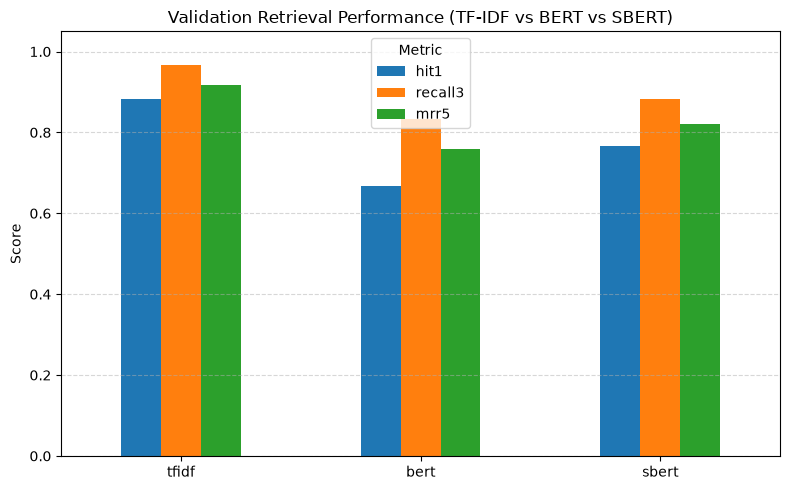

In [29]:
# [학생 구현] CP-08 — Sentence-BERT 검색 + 성능 비교


def search_sbert(query, k=5):
    """
    [기능] 사용자 질문 1개를 Sentence-BERT 벡터로 변환한 뒤,
           전체 SBERT 문서 벡터와 코사인 유사도를 계산해 상위 k개 문서를 반환하는 함수

    [파라미터]
      - query : 검색할 질문 문자열
      - k     : 반환할 상위 문서 개수 (기본값=5)

    ▶ [리턴값] 유사도가 높은 순서대로 정렬된 상위 k개 문서 정보 리스트
      - 형태: [{'rank': 1, 'doc_id': ..., 'score': ..., 'text': ...}, ...]
    """
    # ★ 1. 입력 질문을 문자열로 통일 (캐시 딕셔너리 키 형식 str(q)와 일치시키기 위함)
    query = str(query)

    # ★ 2. 질문 벡터(768,) 준비
    #   - 캐시(sbert_query_cache)에 이미 있으면 재계산 없이 바로 꺼내 사용
    #   - 캐시에 없는 새 질문이면 SBERT 모델로 계산 (문서 벡터와 조건을 맞추기 위해 정규화·NumPy 변환 옵션 동일 적용)
    #   - encode([query])는 (1, 768) 2차원 배열을 반환하므로 [0]을 붙여 (768,) 1차원 벡터로 추출
    if query in sbert_query_cache:
        query_vec = sbert_query_cache[query]
    else:
        query_vec = sbert_model.encode(
            [query], normalize_embeddings=True, convert_to_numpy=True
        )[0]

    # ★ 3. SBERT 질문 벡터(768,)와 전체 SBERT 문서 벡터(200, 768)의 코사인 유사도 계산
    #   - 일반 BERT 벡터가 아닌, 반드시 같은 SBERT 모델이 만든 sbert_doc_vectors와 비교해야 함
    scores = cosine_scores(query_vec, sbert_doc_vectors)

    # ▶ [리턴 결과] 유사도 점수가 높은 순서대로 상위 k개 문서 결과 반환
    return top_k_results(scores, corpus_df, k=k)


# ★ 4. 검증 데이터(60문항) 전체를 대상으로 SBERT 검색기 채점
#   - sbert_summary : 전체 평균 성적표 (hit1, recall3, mrr5)
#   - sbert_detail  : 문항별 상세 채점표 (DataFrame)
sbert_summary, sbert_detail = evaluate_search(search_sbert, valid_df)

# ★ 5. 세 검색 방식(TF-IDF, BERT, SBERT)의 평균 성적표를 하나의 비교표(DataFrame)로 합치기
#   - orient='index' : 딕셔너리 키('tfidf', 'bert', 'sbert')를 표의 행 이름으로 사용
#   - [['hit1', 'recall3', 'mrr5']] : 열 순서를 지표 순서대로 고정
comparison_df = pd.DataFrame.from_dict(
    {
        'tfidf': tfidf_summary,
        'bert': bert_summary,
        'sbert': sbert_summary,
    },
    orient='index',
)[['hit1', 'recall3', 'mrr5']]

# ▶ [출력 결과 1] 세 모델의 Validation 성능 비교표를 소수점 3자리까지 출력
display(comparison_df.round(3))

# ★ 6. 비교표를 CSV 파일로 저장 (한글·특수문자 깨짐 방지를 위해 utf-8-sig 인코딩 사용)
comparison_df.to_csv(TABLES / 'cp08_validation_comparison.csv', encoding='utf-8-sig')

# ★ 7. 세 모델의 점수를 나란히 비교하는 막대그래프 생성 및 꾸미기
#   - rot=0 : x축 모델 이름('tfidf', 'bert', 'sbert')을 가로로 똑바로 표시
ax = comparison_df.plot(kind='bar', rot=0, figsize=(8, 5))
ax.set_title('Validation Retrieval Performance (TF-IDF vs BERT vs SBERT)')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)                          # 지표 범위가 0~1이므로 위쪽 여백을 살짝 확보
ax.grid(axis='y', linestyle='--', alpha=0.5)  # 점수 비교를 돕는 가로 점선 눈금 추가
ax.legend(title='Metric')

# ★ 8. 여백 자동 정리 후 이미지 파일로 저장 및 화면 출력
# ▶ [출력 결과 2] outputs/figures/cp08_validation_comparison.png 저장 및 그래프 출력
plt.tight_layout()
plt.savefig(FIGURES / 'cp08_validation_comparison.png', dpi=150)
plt.show()

**비교 결과 검증(공통).** 세 검색기의 검색 결과 형식이 같고 지표가 0~1 사이인지 확인합니다. 성능의 순위는 데이터에 따라 달라지므로 BERT나 Sentence-BERT가 무조건 높아야 한다는 조건은 없습니다.


In [30]:
# [공통 검증] CP-08

# ★ 1. 비교표(comparison_df)의 행 이름과 순서 검증
#   - 정확히 ['tfidf', 'bert', 'sbert'] 순서로 들어 있는지 확인
_index_list = comparison_df.index.tolist()
print('1) 모델 행 순서:', _index_list)
assert _index_list == ['tfidf', 'bert', 'sbert']

# ★ 2. 모든 평가 지표(hit1, recall3, mrr5)가 0 이상 1 이하의 정상 범위인지 검증
_metrics_df = comparison_df[['hit1', 'recall3', 'mrr5']]
_in_range = bool((_metrics_df >= 0).all().all() and (_metrics_df <= 1).all().all())
print('2) 지표 최솟값 / 최댓값:', round(float(_metrics_df.min().min()), 3), '/', round(float(_metrics_df.max().max()), 3),
      '| 범위 정상 여부:', _in_range)
assert (_metrics_df >= 0).all().all()
assert (_metrics_df <= 1).all().all()

# ★ 3. SBERT 상세 채점표(sbert_detail)의 행 개수가 검증 데이터(valid_df, 60문항)와 일치하는지 검증
print('3) SBERT 채점 문항 수 / 원본 수:', len(sbert_detail), '/', len(valid_df))
assert len(sbert_detail) == len(valid_df)

# ★ 4. search_sbert() 첫 번째 결과의 순위(rank)가 1로 시작하는지 검증
_first_hit = search_sbert(valid_df.iloc[0]['question'], 3)[0]
print('4) 첫 번째 검색 결과 rank:', _first_hit['rank'], '| doc_id:', _first_hit['doc_id'])
assert _first_hit['rank'] == 1

# ▶ [출력 결과] 위 4가지 검증을 모두 통과했을 때만 최종 통과 메시지 출력
print('\nCP-08 통과: 세 검색 방식의 Validation 평가 완료')

1) 모델 행 순서: ['tfidf', 'bert', 'sbert']
2) 지표 최솟값 / 최댓값: 0.667 / 0.967 | 범위 정상 여부: True
3) SBERT 채점 문항 수 / 원본 수: 60 / 60
4) 첫 번째 검색 결과 rank: 1 | doc_id: D040

CP-08 통과: 세 검색 방식의 Validation 평가 완료


**[기록] 결과 해석 — CP-08**

- **세 검색기의 Hit@1·Recall@3·MRR@5 차이:**
  - **TF-IDF:** Hit@1 0.883 / Recall@3 0.967 / MRR@5 0.917 (모든 지표 1위)
  - **Sentence-BERT:** Hit@1 0.767 / Recall@3 0.883 / MRR@5 0.821 (2위)
  - **일반 BERT:** Hit@1 0.667 / Recall@3 0.833 / MRR@5 0.759 (3위)
  - 특히 1위 적중률인 **Hit@1**에서 격차가 가장 컸음 (TF-IDF가 SBERT보다 0.116, 일반 BERT보다 0.216 높음)

- **예상과 다른 결과가 있다면 가능 원인:**
  - **TF-IDF가 딥러닝 모델보다 높은 이유**
    - 문자 2~3-gram 방식이라 한국어 띄어쓰기 영향을 덜 받음
    - 질문과 정답 문단에 핵심 키워드·표현이 직접 겹치는 문항에서 매우 강함
    - BERT·SBERT는 최대 256토큰 제한으로 문서 뒷부분 정보가 일부 잘렸을 수 있음
    - 정답 문서가 문항당 1개만 지정되어, 의미가 비슷한 다른 문단을 찾아도 오답 처리됨
  - **일반 BERT가 Sentence-BERT보다 낮은 이유**
    - 일반 BERT(klue/bert-base)는 문장 간 유사도 검색용으로 추가 학습되지 않음
    - Mean Pooling 시 [CLS]·[SEP] 같은 특수 토큰도 평균에 포함됨
    - 반면 Sentence-BERT(KR-SBERT)는 문장 의미 관계를 벡터에 반영하도록 학습되어 더 유리함

**[CP-08 완료 기준]** 세 방식의 동일 Validation 질문 비교표·그래프와 결과 해석을 완성합니다.


---
## CP-09. 검색 실패 사례 분석 및 최종 검색 방식 선정

성능 지표가 비슷하더라도 어떤 질문을 잘 찾고, 어떤 질문에서 실패하는지는 다를 수 있습니다. CP-01에서 세운 가설을 실제 Validation 검색 오류와 비교한 뒤 활용 목적에 맞는 검색 방식을 직접 선택합니다.


**검색 실패 질의 분석(학생 구현).** 세 검색기의 질문별 Hit@1을 합쳐 실패한 질문을 5개 이상 선정합니다. 세 검색기의 상위 문서와 정답 문서 ID를 나란히 비교하고 오류 원인을 기록합니다.


In [31]:
# [학생 구현] CP-09 — 질문별 성공/실패 비교 및 대표 오류 선택

# ★ 1. 비교 표의 기준이 될 검증 질문 목록(query_id, question, relevant_doc_id) 복사
error_df = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()

# ★ 2. 세 모델(TF-IDF, BERT, SBERT)의 상세 채점표를 query_id 기준으로 차례대로 병합
#   - 모델 간 열 이름이 겹치지 않도록 앞에 모델명 접두사(tfidf_, bert_, sbert_)를 붙임
#   - 각 모델이 1위로 예측한 문서 ID(top1_doc_id)도 함께 가져와 정답과 대조할 수 있게 함
for name, detail in [('tfidf', tfidf_detail), ('bert', bert_detail), ('sbert', sbert_detail)]:
    sub = detail[['query_id', 'hit1', 'recall3', 'rank', 'top1_doc_id']].rename(
        columns={
            'hit1': f'{name}_hit1',
            'recall3': f'{name}_recall3',
            'rank': f'{name}_rank',
            'top1_doc_id': f'{name}_top1',
        }
    )
    error_df = error_df.merge(sub, on='query_id', how='left')

# ★ 3. CP-01에서 구한 질문-정답 간 글자 겹침 비율(overlap) 병합
#   - 실패한 질문이 원래 단어 겹침이 적은 질문이었는지 함께 확인하기 위함
error_df = error_df.merge(valid_overlap[['query_id', 'overlap']], on='query_id', how='left')

# ★ 4. 질문별 Top-1 실패 횟수 계산 (3 - 세 모델의 hit1 합계)
#   - 세 모델 모두 1위 정답이면 3 - 3 = 0, 모두 실패하면 3 - 0 = 3 (값이 클수록 많이 틀린 질문)
error_df['num_top1_failures'] = 3 - (
    error_df['tfidf_hit1'] + error_df['bert_hit1'] + error_df['sbert_hit1']
)

# ★ 5. 실패 횟수가 가장 많은 상위 5개 질문을 대표 오류(error_cases)로 추출
# ▶ [출력 결과 1] 대표 실패 질문 5건 표 출력
error_cases = error_df.sort_values('num_top1_failures', ascending=False).head(5).copy()
display(error_cases)

# ★ 6. 대표 실패 질문 첫 번째 항목(0번 행)을 꺼내 세 검색기의 Top-3 결과 직접 비교
# ▶ [출력 결과 2] 대표 질문 1건에 대한 모델별 Top-3 (순위, 문서ID, 유사도 점수) 출력
target_row = error_cases.iloc[0]
print(f"대표 질문 [{target_row['query_id']}] (정답: {target_row['relevant_doc_id']}): {target_row['question']}")

for label, fn in [('TF-IDF', search_tfidf), ('BERT', search_bert), ('SBERT', search_sbert)]:
    hits = fn(target_row['question'], 3)
    top3_info = [(h['rank'], h['doc_id'], round(h['score'], 4)) for h in hits]
    print(f"  - {label:6s} Top-3: {top3_info}")

# ★ 7. 추출한 대표 오류 5건 표를 CSV 파일로 저장 (한글 깨짐 방지를 위해 utf-8-sig 인코딩 사용)
error_cases.to_csv(TABLES / 'cp09_error_cases.csv', index=False, encoding='utf-8-sig')

,query_id,question,relevant_doc_id,tfidf_hit1,tfidf_recall3,tfidf_rank,tfidf_top1,bert_hit1,bert_recall3,bert_rank,bert_top1,sbert_hit1,sbert_recall3,sbert_rank,sbert_top1,overlap,num_top1_failures
19,QV020,소넨이 상을 받았던 해는?,D138,0,0,NaN,D004,0,0,NaN,D146,0,0,NaN,D040,0.428571,3
46,QV047,자바 API를 개발한 회사는 어디인가?,D048,0,0,NaN,D013,0,0,NaN,D013,0,0,4.0,D083,0.333333,3
13,QV014,이순몽 장군의 자택이 설립된 시기는?,D170,1,1,1.0,D170,0,0,NaN,D134,0,0,NaN,D134,0.363636,2
18,QV019,오브스테트릭스의 뜻에 대해 연구한 사람은?,D128,1,1,1.0,D128,0,0,NaN,D015,0,0,NaN,D131,0.500000,2
23,QV024,이윤필의 아버지는 누구인가?,D134,0,1,2.0,D020,0,1,2.0,D007,1,1,1.0,D134,0.500000,2


대표 질문 [QV020] (정답: D138): 소넨이 상을 받았던 해는?
  - TF-IDF Top-3: [(1, 'D004', 0.1033), (2, 'D041', 0.0505), (3, 'D105', 0.0503)]
  - BERT   Top-3: [(1, 'D146', 0.6404), (2, 'D183', 0.6388), (3, 'D069', 0.6342)]
  - SBERT  Top-3: [(1, 'D040', 0.3843), (2, 'D004', 0.3389), (3, 'D015', 0.3259)]


**[기록] 결과 해석 — CP-09**

- **대표 실패 질문 5개에서 확인한 원인 (표면 단어 불일치, 문서 길이, 의미 혼동 등):**
  - **QV020 (소넨이 상을 받았던 해, 모두 실패):** 정답 문단(D138)에 "상을 받다" 대신 "공로를 인정받았다"로 적혀 있음. 세 모델 모두 "소넨"보다 "수상/상" 표현이 많은 다른 문서(D004, D146 등)를 1위로 뽑는 의미·키워드 혼동이 발생함.
  - **QV047 (자바 API 개발 회사, 모두 1위 실패):** 정답 문단(D048) 대부분이 오라클-구글 저작권 소송 내용이고 "개발 회사"라는 직접 표현이 없음. "API"도 "응용프로그램 인터페이스(API)"로 풀어 쓰여 표면 단어가 어긋남(SBERT만 4위로 찾음).
  - **QV014 (이순몽 장군 자택 설립 시기, BERT·SBERT 실패):** 정답 문단(D170)에 "자택/설립" 대신 "집/지은 건물"이라는 유의어가 쓰임. 표면 단어 불일치에도 TF-IDF는 고유명사("이순몽 장군의") 일치로 1위를 맞힘.
  - **QV019 (오브스테트릭스 뜻 연구자, BERT·SBERT 실패):** 정답 문단(D128) 앞부분은 아그노디케 재판 이야기이고 핵심 단어 "오브스테트릭스"와 연구자 이름은 맨 뒷문단에 나옴. 딥러닝 모델은 긴 문맥 속에서 뒷부분 핵심 정보가 희석된 반면, TF-IDF는 희귀 단어 일치로 1위를 맞힘.
  - **QV024 (이윤필의 아버지, TF-IDF·BERT 실패):** 정답 문단(D134)은 동생 "이규완" 중심 글이라 "아버지 이기혁"(첫 문단)과 "형 이윤필"(셋째 문단) 정보가 떨어져 있음. 문맥 연결이 필요한 질문에서 SBERT만 1위로 맞히고 TF-IDF·BERT는 2위에 머무름.

- **실패한 질문의 겹침 비율(CP-01)은 전체 평균과 비교해 어떤가? 겹침이 낮은 질문은 어느 검색기가 더 잘 찾았는가?:**
  - Validation 전체 60문항의 평균 겹침 비율은 0.474임.
  - 대표 실패 질문 5개의 겹침 비율은 평균 0.425로 전체 평균보다 낮음(특히 QV047은 0.333, QV014는 0.364, QV020은 0.429로 낮음).
  - 겹침이 낮은 질문 중 고유명사가 살아 있는 질문(QV014)은 TF-IDF가 찾았고, 문장 표현이 크게 달라진 질문(QV047)은 SBERT만 5위권(4위) 안에 포함시킴.

- **CP-01에서 예상한 TF-IDF/BERT의 장단점이 실제로 확인되었는가?:**
  - 대체로 확인되었음. TF-IDF는 고유명사·희귀어가 포함된 질문(QV014, QV019)에서 강점을 보였음.
  - 반대로 표현이 바뀌거나 문맥 연결이 필요한 질문(QV024)에서는 SBERT가 1위로 맞히며 의미 검색의 장점을 보였음.
  - 다만 일반 BERT는 문장 유사도용 추가 학습이 없어 예상보다 검색 정확도가 전반적으로 낮았음.

- **어떤 질문 유형에서 최종 검색기가 특히 좋은/나쁜 결과를 보이는가?:**
  - Validation 전체 1위인 TF-IDF(Hit@1 0.883, Recall@3 0.967, MRR@5 0.917)를 최종 검색기로 선택할 경우를 기준으로 정리함.
  - **좋은 결과를 보이는 유형:** 질문에 고유명사, 숫자, 전문 용어 등 핵심 키워드가 직접 등장하고 문단에도 같은 표현이 남아 있는 사실 확인형 질문.
  - **나쁜 결과를 보이는 유형:** 질문의 단어가 문단에서 다른 유의어로 바뀌어 쓰였거나(표면 단어 불일치), 여러 문장에 걸친 인물·사건 관계를 추론해야 하는 질문.

**최종 검색 방식 선정(학생 구현).** 실제 활용 목적과 가장 중요한 검색 지표를 정의한 후 Validation 결과에 근거해 검색 방식을 선택합니다. 선택값·대안·트레이드오프를 JSON으로 저장하면 최종 ADR의 근거로 활용할 수 있습니다.


In [32]:
# [학생 구현] CP-09 — 사용 목적 및 선택 근거
# TODO 9-6. 검색기를 사용할 실제 상황을 USE_CASE로 한 문장 작성하세요.
USE_CASE = '책 관련 키워드만 입력하면 띄어쓰기·오타가 있어도 GPU 없이 찾아주는 도서 검색기'


# TODO 9-7. PRIORITY_METRIC을 'hit1', 'recall3', 'mrr5' 중 하나로 지정하세요.
PRIORITY_METRIC = 'recall3'


# TODO 9-8. comparison_df의 Validation 점수와 오류 사례를 고려하여
#             SELECTED_METHOD를 'tfidf', 'bert', 'sbert' 중 하나로 직접 선택하세요.
SELECTED_METHOD = 'tfidf'

# TODO 9-9. SELECTION_REASON에 실제 수치와 다른 방법의 장단점을 2~3문장으로 적으세요.
SELECTION_REASON = (
    'TF-IDF는 Recall@3 0.967(Hit@1 0.883, MRR@5 0.917)로 가장 높아 선택했습니다. '
    'SBERT(0.883)는 문맥 이해는 좋았으나 키워드 매칭이 약했습니다. '
    '일반 BERT(0.833)는 유사도 학습이 없어 성능이 가장 낮았습니다.'
)

assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')
selection = {'use_case': USE_CASE, 'priority_metric': PRIORITY_METRIC,
             'selected_method': SELECTED_METHOD, 'selection_reason': SELECTION_REASON,
             'validation_metrics': comparison_df.reset_index().to_dict('records')}
(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)



선정 모델: tfidf | 우선 지표: recall3


**[CP-09 완료 기준]** 검색 실패 질문 5건을 분석하고, CP-01의 가설을 검증합니다. 사용 목적·우선 지표·선택 검색기·근거를 기록한 `cp09_selection.json`을 저장합니다.


---
## CP-10. 최종 `search_docs()` 완성 및 보류 Test 검증

CP-09에서 선택한 검색 방식을 하나의 사용자 함수 `search_docs()`로 연결합니다. **선택한 방법은 Test 결과를 확인한 뒤 바꾸지 않으며**, 새로운 질문에서도 최종 검색기가 동작하는지 확인합니다.


**최종 검색 함수(학생 구현).** 저장된 선택값에 맞춰 TF-IDF/BERT/Sentence-BERT 함수를 호출하고 Top-k 문서를 반환합니다. 이후 처음으로 Test 질문을 읽어 별도 데이터에서의 최종 성능을 검증합니다.


In [33]:
# [학생 구현] CP-10 — 최종 검색기 인터페이스

def search_docs(query, k=3, method=SELECTED_METHOD):
    """선택한 검색 방식의 상위 k개 문서 반환."""

    # ★ 1. 전달받은 검색 방식(method)에 따라 해당 검색 함수 호출
    #   - method를 생략하면 CP-09에서 선정한 SELECTED_METHOD('tfidf')가 기본값으로 적용됨
    if method == 'tfidf':
        results = search_tfidf(query, k=k)
    elif method == 'bert':
        results = search_bert(query, k=k)
    elif method == 'sbert':
        results = search_sbert(query, k=k)
    else:
        # 허용된 3가지 방식 외의 값이 들어오면 예외 발생
        raise ValueError(f"지원하지 않는 검색 방식입니다: {method}")

    # ★ 2. 세 검색기 모두 top_k_results()를 거쳐 동일한 구조(rank/doc_id/score/text)로 반환
    return results

# ★ 3. 검증 데이터에 없는 새로운 질문을 직접 작성해 최종 검색기 테스트
my_question = '자바API는 오라클에서 어떻게 할까?'
# my_question = '마이크로소프트가 수십억 달러를 투자하려던 PC 기업은?'
# my_question = '한국신용데이터가 출시한 맛집 정보 앱 이름은 무엇인가요?'

# ▶ [출력 결과] 입력 질문과 최종 모델(TF-IDF) 기준 상위 3개 검색 결과 표 출력
print('내 질문:', my_question)
display(pd.DataFrame(search_docs(my_question, k=3)))

내 질문: 자바API는 오라클에서 어떻게 할까?


,rank,doc_id,score,text
0,1,D048,0.187042,미국 항소법원이 오라클과 구글의 저작권 침해 손해배상소송에서 “프로그램에도 저작권에...
1,2,D114,0.059735,"어나오는 인생의 장애물들, 특별한 여성들은 어떻게 극복했을까. 《해리포터》를 쓴 조..."
2,3,D018,0.054130,00여명 신청했다. 금오공대에 다니는 이해인 씨는 “삼성전자 인사담당자에게 어떻게 ...


**보류 Test 평가·저장(학생 구현).** CP-09의 선택을 고정한 채 Test 질문 20개를 처음으로 평가합니다. Validation과 Test의 성능 차이 및 데이터 한계를 기록하고 CSV·JSON 결과를 출력합니다.


In [34]:
# [학생 구현] CP-10 — 보류 Test 최종 평가 (이 셀에서 Test 정답을 처음 사용)

# ★ 1. 보류해 두었던 Test 데이터(20문항) 로드 및 문항 수 검증
test_df = pd.read_csv(TEST_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(test_df) == 20


# TODO 10-4. SELECTED_METHOD를 바꾸지 않고 search_docs()로 Test 질문 20개를 평가하고
#            결과를 test_summary, test_detail이라는 이름으로 받으세요.
test_summary, test_detail = evaluate_search(search_docs, test_df)


# TODO 10-5. comparison_df의 선택 모델 Validation 점수와 Test 점수를 final_compare라는 DataFrame으로
#            정리하세요. 행은 Validation, Test 두 개입니다.
final_compare = pd.DataFrame.from_dict(
    {
        'Validation': comparison_df.loc[SELECTED_METHOD].to_dict(),
        'Test': test_summary,
    },
    orient='index',
)[['hit1', 'recall3', 'mrr5']]
display(final_compare.round(3))

# TODO 10-6. final_compare는 TABLES / 'cp10_validation_test_comparison.csv'로,
#            test_detail은 TABLES / 'cp10_test_query_results.csv'로 저장하세요.
final_compare.to_csv(TABLES / 'cp10_validation_test_comparison.csv', encoding='utf-8-sig')
test_detail.to_csv(TABLES / 'cp10_test_query_results.csv', index=False, encoding='utf-8-sig')


# TODO 10-7. 선택 방법, 우선 지표, Validation·Test 점수를 REPORTS / 'cp10_final_report.json'에 저장하세요.
# [주의] 검증 셀이 위 변수 이름과 파일 이름을 그대로 확인합니다.
final_report = {
    'selected_method': SELECTED_METHOD,
    'priority_metric': PRIORITY_METRIC,
    'validation': {k: float(v) for k, v in comparison_df.loc[SELECTED_METHOD].items()},
    'test': {k: float(v) for k, v in test_summary.items()},
}

(REPORTS / 'cp10_final_report.json').write_text(
    json.dumps(final_report, ensure_ascii=False, indent=2), encoding='utf-8'
)




,hit1,recall3,mrr5
Validation,0.883,0.967,0.917
Test,0.800,0.800,0.812


258

**최종 프로젝트 검증(공통).** Test 데이터는 더 이상 모델 선택에 사용하지 않습니다. 두 분할의 성능표와 JSON을 저장했는지 확인하고, 최종 검색 함수가 사용자가 입력한 질문에서 정상 동작하는지 점검합니다.


In [35]:
# [공통 검증] CP-10
# 1) Test 20문항의 문항별 상세 채점표(test_detail)가 빠짐없이 20줄인지 확인
assert len(test_detail) == 20
print(f'[1] test_detail 행 개수 확인: {len(test_detail)}행')

# 2) Validation과 Test 성적을 나란히 비교한 표(final_compare)가 정확히 2줄인지 확인
assert len(final_compare) == 2
print(f'[2] final_compare 행 개수 확인: {len(final_compare)}행 ({list(final_compare.index)})')

# 3) outputs/tables/ 폴더 안에 비교표 CSV와 Test 상세 결과 CSV 파일 2개가 실제로 저장되었는지 확인
csv_files = ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv']
assert all((TABLES / n).is_file() for n in csv_files)
print(f'[3] TABLES CSV 파일 저장 확인: {csv_files}')

# 4) outputs/reports/ 폴더 안에 최종 요약 보고서 JSON 파일이 실제로 저장되었는지 확인
assert (REPORTS / 'cp10_final_report.json').is_file()
print("[4] REPORTS JSON 파일 저장 확인: 'cp10_final_report.json'")

# 5) 최종 검색기(search_docs)에 테스트 질문을 넣고 3개를 뽑았을 때,
#    첫 번째(0번째) 결과의 rank 값이 1로 정상 반환되는지 동작 확인
sample_top1 = search_docs('이 기사에서 설명하는 현상은 무엇인가요?', 3)[0]
assert sample_top1['rank'] == 1
print(f"[5] search_docs() 1위 반환 확인: rank={sample_top1['rank']}, doc_id={sample_top1['doc_id']}, score={sample_top1['score']:.4f}")

# 위 5가지 최종 검사를 모두 에러 없이 통과하면 프로젝트 완료 메시지 출력
print('CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료')

[1] test_detail 행 개수 확인: 20행
[2] final_compare 행 개수 확인: 2행 (['Validation', 'Test'])
[3] TABLES CSV 파일 저장 확인: ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv']
[4] REPORTS JSON 파일 저장 확인: 'cp10_final_report.json'
[5] search_docs() 1위 반환 확인: rank=1, doc_id=D020, score=0.0935
CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료


**[기록] 결과 해석 — CP-10**

- **최종 선택 모델의 Validation 및 Test 지표 차이:**
  - 최종 선택 모델: TF-IDF (문자 2~3-gram)
  - Validation (60문항): Hit@1 0.883 / Recall@3 0.967 / MRR@5 0.917
  - Test (20문항): Hit@1 0.800 / Recall@3 0.800 / MRR@5 0.812
  - Validation 대비 Test에서 Hit@1은 0.083, Recall@3은 0.167, MRR@5는 0.105 하락함
  - Test 문항 수(20개)가 적어 한두 문항의 오답이 전체 점수에 크게 반영됨

- **검색에 실패한 Test 질문의 특징과 예상 원인:**
  - 총 4개 문항(QT003, QT009, QT012, QT016)에서 1위 검색에 실패함 (QT012만 4위, 나머지 3건은 5위 밖)
  - 질문의 핵심 표현이 정답 문단에서 다른 유의어로 바뀌어 쓰인 경우가 많음
    - QT016: 질문은 "투자에 적극적인"이나 정답 문단(D137)은 "활발한 투자를 벌이고 있다"로 표현됨
    - QT003: 질문은 "발표한 인물의 이름은"이나 정답 문단(D042)은 "프레젠테이션을 하며 질문에 답했다"로 표현됨
  - 1글자 키워드나 띄어쓰기 차이로 문자 N-gram 매칭에 불리한 경우가 있음
    - QT012: 핵심 대상이 1글자 초성체("ㅋ")라 문자 2~3-gram으로 포착하기 어려움
    - QT009: "척수근육 위축증"과 문단(D004)의 "척수근육위축증" 간 띄어쓰기 차이가 있고, "인물/명칭" 같은 일반 표현이 다른 문서에 밀림

- **이 작은 KLUE-MRC 변환 데이터로 실제 업무 검색 품질을 보장할 수 없는 이유:**
  - 문서 200개, 질문 80개(Validation 60·Test 20) 규모로 실제 서비스 환경에 비해 매우 작음
  - 500자 이내 문단만 잘라낸 MRC 데이터라, 길고 형식이 다양한 실무 문서(PDF·보고서·매뉴얼)와 다름
  - 질문당 정답을 1개만 지정한 구조라, 여러 문서에 답이 분산된 실제 검색 상황을 반영하지 못함
  - 뉴스·위키 사실 확인형 질문 위주라 실무의 전문 용어·약어·오타·구어체 질의 성능을 보장하기 어려움

### CP-10 종료 후 — 프로젝트 문서 작성 (별도 제출, 체크포인트에 포함되지 않음)

1. **프로젝트 명세서:** 입력·출력, 데이터셋, 세 검색기의 역할과 주요 함수
2. **ADR:** USE_CASE, PRIORITY_METRIC, SELECTED_METHOD, SELECTION_REASON 및 비교한 대안
3. **결과 분석 문서:** CP-01 가설, CP-08 비교표, CP-09 실패 사례, CP-10 Test 평가·한계


**[최종 완료 기준]** CP-01~10 구현·검증, 선택 근거 기록, 보류 Test 평가, 필수 문서 작성 후 Notebook을 GitHub에 Push합니다. 다운로드한 원본 문서·대형 모델 가중치는 GitHub에 올리지 않습니다.